# Assignment 1 Title: Comparing Classical Machine Learning and Neural Network


**Module:** 6FTC2175 Advanced Machine Learning and Neural Network (ANLNN)/  **Student:** parina roshan sharma
**ID:** 25370M55

This notebook follows the assignment structure:

| Section | Content |
|---|---|
| 1 |  - Tabular data preparation (Manufacturing Defects) |
| 2 |  - Classical ML model (Random Forest) |
| 3 |  - Feed-forward neural network (MLP) |
| 4 |  - Image data preparation (Casting Product Images) |
| 5 |  - CNN experiments (baseline vs revised) |
| 6 |- Critical comparison and deployment recommendation |



In [1]:
# Global setup used by every section
import os, time, random, warnings, zipfile, io, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

import tensorflow as tf
tf.random.set_seed(SEED)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

# A shared dictionary where every model stores its test results for Part C
RESULTS = {}

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# 1. Part A - Tabular Data Preparation

## 1.1 Purpose and honest statement of limitations
We use the Kaggle **Manufacturing Defects** dataset (*Predicting Manufacturing Defects*,
`rabieelkharoua/predicting-manufacturing-defects-dataset`). Each row is a production record with process and
operational metrics and a binary target **`DefectStatus`** (1 = defective, 0 = not defective).

>

In [2]:
# 1.2 Load the dataset from Kaggle (kagglehub; falls back to a manual CSV upload)
!pip -q install kagglehub
import kagglehub, glob

def load_manufacturing_defects():
    try:
        p = kagglehub.dataset_download("rabieelkharoua/predicting-manufacturing-defects-dataset")
        csvs = glob.glob(os.path.join(p, "**", "*.csv"), recursive=True)
        print("CSV files found:", csvs)
        return pd.read_csv(csvs[0])
    except Exception as e:
        print("Automatic download failed:", e)
        print("Download the CSV from the Kaggle page and upload it here.")
        from google.colab import files
        up = files.upload()
        return pd.read_csv(list(up.keys())[0])

df = load_manufacturing_defects()
df.columns = [c.strip() for c in df.columns]
df.head()

100%|██████████| 363k/363k [00:00<00:00, 459kB/s]

Extracting files...
CSV files found: ['/root/.cache/kagglehub/datasets/rabieelkharoua/predicting-manufacturing-defects-dataset/versions/1/manufacturing_defect_dataset.csv']


,ProductionVolume,ProductionCost,SupplierQuality,DeliveryDelay,DefectRate,QualityScore,MaintenanceHours,DowntimePercentage,InventoryTurnover,StockoutRate,WorkerProductivity,SafetyIncidents,EnergyConsumption,EnergyEfficiency,AdditiveProcessTime,AdditiveMaterialCost,DefectStatus
0,202,13175.403783,86.648534,1,3.121492,63.463494,9,0.052343,8.630515,0.081322,85.042379,0,2419.616785,0.468947,5.551639,236.439301,1
1,535,19770.046093,86.310664,4,0.819531,83.697818,20,4.908328,9.296598,0.038486,99.657443,7,3915.566713,0.119485,9.080754,353.957631,1
2,960,19060.820997,82.132472,0,4.514504,90.350550,1,2.464923,5.097486,0.002887,92.819264,2,3392.385362,0.496392,6.562827,396.189402,1
3,370,5647.606037,87.335966,5,0.638524,67.628690,8,4.692476,3.577616,0.055331,96.887013,8,4652.400275,0.183125,8.097496,164.135870,1
4,206,7472.222236,81.989893,3,3.867784,82.728334,9,2.746726,6.851709,0.068047,88.315554,7,1581.630332,0.263507,6.406154,365.708964,1


In [3]:
# 1.3 VERIFY the dataset and the target column, then inspect everything
TARGET = "DefectStatus"

# (a) Does the downloaded CSV actually contain the target? Fail loudly (with the real column list) if not.
if TARGET not in df.columns:
    raise KeyError(f"'{TARGET}' not found. Columns in the downloaded file are: {list(df.columns)}. "
                   "Pick the correct target column (or the wrong CSV was downloaded) and update TARGET.")
print(f"OK: target column '{TARGET}' is present.")

# (b) Is the target binary 0/1?
print("Target values:", sorted(df[TARGET].dropna().unique().tolist()))
assert set(df[TARGET].dropna().unique()) <= {0, 1}, "Target is not binary 0/1 - recode before continuing."

# (c) Inspect all feature names, types, missing values, duplicates
print("\nShape:", df.shape)
print("\nAll columns:", list(df.columns))
print("\nFeature columns (everything except the target):", [c for c in df.columns if c != TARGET])
print()
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# (d) Target-class counts
vc = df[TARGET].value_counts().sort_index()
print("\nTarget-class counts:\n", pd.DataFrame({"count": vc, "percent": (vc / len(df) * 100).round(2)}))
df.describe().T

OK: target column 'DefectStatus' is present.
Target values: [0, 1]

Shape: (3240, 17)

All columns: ['ProductionVolume', 'ProductionCost', 'SupplierQuality', 'DeliveryDelay', 'DefectRate', 'QualityScore', 'MaintenanceHours', 'DowntimePercentage', 'InventoryTurnover', 'StockoutRate', 'WorkerProductivity', 'SafetyIncidents', 'EnergyConsumption', 'EnergyEfficiency', 'AdditiveProcessTime', 'AdditiveMaterialCost', 'DefectStatus']

Feature columns (everything except the target): ['ProductionVolume', 'ProductionCost', 'SupplierQuality', 'DeliveryDelay', 'DefectRate', 'QualityScore', 'MaintenanceHours', 'DowntimePercentage', 'InventoryTurnover', 'StockoutRate', 'WorkerProductivity', 'SafetyIncidents', 'EnergyConsumption', 'EnergyEfficiency', 'AdditiveProcessTime', 'AdditiveMaterialCost']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3240 entries, 0 to 3239
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  

,count,mean,std,min,25%,50%,75%,max
ProductionVolume,3240.0,548.523148,262.402073,100.000000,322.000000,549.000000,775.250000,999.000000
ProductionCost,3240.0,12423.018476,4308.051904,5000.174521,8728.829280,12405.204656,16124.462428,19993.365549
SupplierQuality,3240.0,89.833290,5.759143,80.004820,84.869219,89.704861,94.789936,99.989214
DeliveryDelay,3240.0,2.558951,1.705804,0.000000,1.000000,3.000000,4.000000,5.000000
DefectRate,3240.0,2.749116,1.310154,0.500710,1.598033,2.708775,3.904533,4.998529
QualityScore,3240.0,80.134272,11.611750,60.010098,70.103420,80.265312,90.353822,99.996993
MaintenanceHours,3240.0,11.476543,6.872684,0.000000,5.750000,12.000000,17.000000,23.000000
DowntimePercentage,3240.0,2.501373,1.443684,0.001665,1.264597,2.465151,3.774861,4.997591
InventoryTurnover,3240.0,6.019662,2.329791,2.001611,3.983249,6.022389,8.050222,9.998577
StockoutRate,3240.0,0.050878,0.028797,0.000002,0.026200,0.051837,0.075473,0.099997


Majority-class baseline accuracy (always predict the majority class): 84.04%


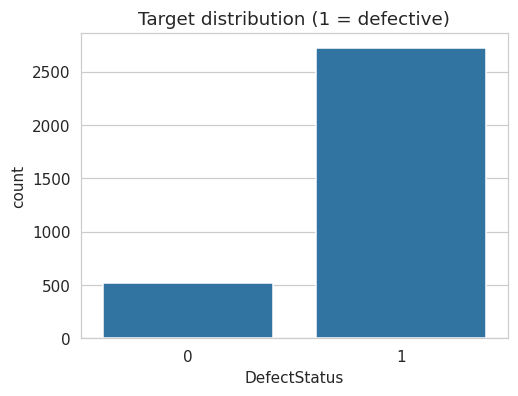

In [4]:
# 1.4 Explore the target-class distribution
pct = df[TARGET].value_counts(normalize=True).sort_index() * 100
print("Majority-class baseline accuracy (always predict the majority class): %.2f%%" % pct.max())

fig, ax = plt.subplots(figsize=(5, 3.6))
sns.countplot(x=TARGET, data=df, ax=ax); ax.set_title("Target distribution (1 = defective)")
plt.show()

In [5]:
# 1.5 Split into training and test sets FIRST (stratified, shared by BOTH models).
# All later decisions (leakage audit, scaling, tuning) use the TRAINING part only.
from sklearn.model_selection import train_test_split

y_all = df[TARGET].astype(int)
X_all = df.drop(columns=[TARGET])

X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED
)
print("Train:", X_train_all.shape, "| defect rate: %.2f%%" % (100 * y_train.mean()))
print("Test :", X_test_all.shape,  "| defect rate: %.2f%%" % (100 * y_test.mean()))

Train: (2592, 16) | defect rate: 84.03%
Test : (648, 16) | defect rate: 84.10%


,correlation,univariate_AUC,separation,name_suggests_outcome,suspiciously_strong
feature,,,,,
MaintenanceHours,0.309,0.743,0.487,False,False
DefectRate,0.258,0.702,0.405,True,False
QualityScore,-0.204,0.340,0.321,True,False
ProductionVolume,0.122,0.597,0.193,False,False
EnergyEfficiency,-0.040,0.469,0.063,False,False
StockoutRate,0.037,0.529,0.058,False,False
SupplierQuality,0.035,0.528,0.057,False,False
ProductionCost,0.024,0.519,0.038,False,False
EnergyConsumption,0.021,0.516,0.033,False,False


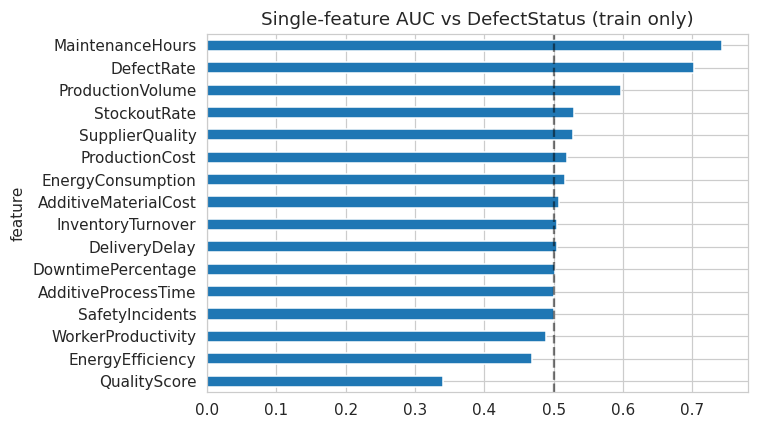

In [6]:
# 1.6 LEAKAGE AUDIT (training data only):
# which features carry information derived from the defect outcome, i.e. would NOT be available
# at the moment a real prediction has to be made?
from sklearn.metrics import roc_auc_score
import re

num_feats = X_train_all.select_dtypes("number")
rows = []
for c in num_feats.columns:
    v = num_feats[c].fillna(num_feats[c].median())
    auc = roc_auc_score(y_train, v)
    rows.append({"feature": c,
                 "correlation": float(np.corrcoef(v, y_train)[0, 1]),
                 "univariate_AUC": auc,
                 "separation": abs(auc - 0.5) * 2})
audit = pd.DataFrame(rows).set_index("feature").sort_values("separation", ascending=False)

# Heuristics: (1) a single feature that almost perfectly separates the classes, or
# (2) a name that describes an outcome / inspection result rather than an input.
OUTCOME_PATTERN = r"defect|quality_?score|reject|scrap|fail|inspect|pass"
audit["name_suggests_outcome"] = [bool(re.search(OUTCOME_PATTERN, c, re.I)) for c in audit.index]
audit["suspiciously_strong"] = audit["separation"] > 0.7
display(audit.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
audit["univariate_AUC"].sort_values().plot.barh(ax=ax)
ax.axvline(0.5, color="k", ls="--", alpha=.5); ax.set_title("Single-feature AUC vs DefectStatus (train only)")
plt.tight_layout(); plt.show()

In [7]:
# 1.7 Remove features that would not be available at prediction time, then check the impact.
SUSPECT = audit.index[audit["name_suggests_outcome"] | audit["suspiciously_strong"]].tolist()
print("Flagged by the audit:", SUSPECT)

# >>> EDIT THESE after reading the Kaggle column descriptions <<<
KEEP_ANYWAY = []   # flagged columns you can justify keeping because they ARE known before the outcome
LEAKY_COLS = [c for c in SUSPECT if c not in KEEP_ANYWAY]
ID_LIKE = [c for c in X_train_all.columns if c.lower() in ("id", "index", "unnamed: 0", "productid", "product_id")]
DROP_COLS = LEAKY_COLS + ID_LIKE
print("Dropped (not available at prediction time or identifiers):", DROP_COLS)

X_train = X_train_all.drop(columns=DROP_COLS)
X_test = X_test_all.drop(columns=DROP_COLS)

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric features kept    :", num_cols)
print("Categorical features kept:", cat_cols)

# Sensitivity check on TRAINING data only: how much does the flagged feature set change a quick Random Forest?
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
quick = RandomForestClassifier(n_estimators=150, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
def cv_ap(Xdf):
    # imputation lives INSIDE the pipeline, so every CV fold learns its medians from its own training part only
    Xn = Xdf.select_dtypes("number")
    pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("rf", quick)])
    return cross_val_score(pipe, Xn, y_train, cv=skf, scoring="average_precision").mean()
print("\nCV PR-AUC with ALL numeric features      : %.3f" % cv_ap(X_train_all))
print("CV PR-AUC after dropping flagged columns: %.3f" % cv_ap(X_train))

Flagged by the audit: ['DefectRate', 'QualityScore']
Dropped (not available at prediction time or identifiers): ['DefectRate', 'QualityScore']
Numeric features kept    : ['ProductionVolume', 'ProductionCost', 'SupplierQuality', 'DeliveryDelay', 'MaintenanceHours', 'DowntimePercentage', 'InventoryTurnover', 'StockoutRate', 'WorkerProductivity', 'SafetyIncidents', 'EnergyConsumption', 'EnergyEfficiency', 'AdditiveProcessTime', 'AdditiveMaterialCost']
Categorical features kept: []

CV PR-AUC with ALL numeric features      : 0.966
CV PR-AUC after dropping flagged columns: 0.947


**Interpretation **

I removed `DefectRate` and `QualityScore` (outcome-derived, not available at prediction time). No identifier columns were present, and no flagged column was kept.

Cross-validated PR-AUC fell from **0.966 to 0.947**. This is a small drop, so the removed columns were helping but were not doing most of the work. The model still performs well without them, and the 0.947 figure is the honest estimate to report because it uses only information available at prediction time.

In [8]:
# 1.8 Preprocess WITHOUT data leakage: a factory returns a FRESH preprocessor each time,
# which is always fitted on training rows only.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

def make_preprocessor():
    # imputer -> scaler: medians / means are learned from the rows the preprocessor is fitted on (training rows only)
    steps = [("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols)]
    if cat_cols:
        steps.append(("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                       ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols))
    return ColumnTransformer(steps)

# Preprocessing used by the Random Forest: fitted on the FULL training set.
preprocessor = make_preprocessor()
X_train_p = preprocessor.fit_transform(X_train)   # fit on train only
X_test_p = preprocessor.transform(X_test)         # transform only

feature_names = list(preprocessor.get_feature_names_out())
print("Processed train:", X_train_p.shape, "| processed test:", X_test_p.shape)
print("Train means of scaled columns (should be ~0):", X_train_p[:, :len(num_cols)].mean(axis=0).round(3))

Processed train: (2592, 14) | processed test: (648, 14)
Train means of scaled columns (should be ~0): [ 0. -0. -0. -0. -0.  0. -0. -0.  0. -0.  0. -0.  0.  0.]



**Interpretation

If the scaler were fitted on the full dataset before splitting, the mean and standard deviation would include test rows. Information about the test distribution would leak into training, and the test score would be slightly optimistic. I avoid this by fitting the imputer and scaler on training rows only and then applying (not refitting) them to the test set. The printed means of about 0 on the scaled training columns confirm the scaler was fitted correctly.

Random Forest does not need scaling, but the MLP does. The MLP gets its own preprocessor in Section 3, fitted only on its training subset, so its validation data never influences the scaling parameters.

---
# 2. Part A - Classical ML Model: Random Forest

## 2.1 Why Random Forest?
- **Nature of the data:** small-to-medium, tabular, low-dimensional, numeric process metrics where defects likely depend on non-linear interactions between several variables (e.g. high volume combined with low supplier quality or little maintenance).
- **Bagging of decision trees** captures non-linearities and interactions without manual feature engineering and is robust to outliers and scale.
- **Handles imbalance** through `class_weight="balanced_subsample"`.
- **Interpretable enough** for engineers: gives feature importances and permutation importances.
- **Low tuning burden** and fast to train on a few thousand rows, which suits a production line.

Alternatives considered: SVM (RBF kernel) needs careful scaling and tuning and gives no native importance; Naive Bayes assumes conditional independence, which is unrealistic for correlated process variables.

In [9]:
# 2.2 Train the model (small grid search with stratified CV on the TRAINING set only)
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

rf_base = RandomForestClassifier(
    class_weight="balanced_subsample", random_state=SEED, n_jobs=-1
)
param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 3, 5],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = GridSearchCV(rf_base, param_grid, scoring="average_precision", cv=cv, n_jobs=-1)

t0 = time.time()
grid.fit(X_train_p, y_train)
rf_train_time = time.time() - t0

rf = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print("Best CV PR-AUC : %.4f" % grid.best_score_)
print("Total tuning + training time: %.1f s" % rf_train_time)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}
Best CV PR-AUC : 0.9501
Total tuning + training time: 156.9 s


In [10]:
# 2.3 Generate test predictions
t0 = time.time()
rf_proba = rf.predict_proba(X_test_p)[:, 1]
rf_pred = (rf_proba >= 0.5).astype(int)
rf_infer_time = time.time() - t0
print("Predicted defective units in test set:", rf_pred.sum(), "of", len(rf_pred))

Predicted defective units in test set: 448 of 648


=== Random Forest (threshold = 0.5) ===
              precision    recall  f1-score   support

          OK      0.350     0.680     0.462       103
   Defective      0.926     0.761     0.836       545

    accuracy                          0.748       648
   macro avg      0.638     0.721     0.649       648
weighted avg      0.835     0.748     0.776       648



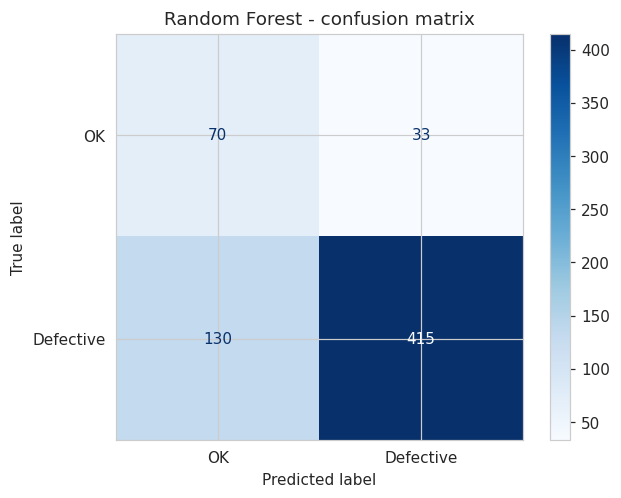

,0
Accuracy,0.748457
Precision,0.926339
Recall,0.761468
F1,0.835851
ROC-AUC,0.748535
PR-AUC,0.924792
Train time (s),156.906481
Parameters,n/a (trees)


In [11]:
# 2.4 Evaluate performance (reusable evaluation function for all tabular models)
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, accuracy_score,
                             precision_recall_curve, roc_curve)

def evaluate_binary(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    res = {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
    }
    print(f"=== {name} (threshold = {threshold}) ===")
    print(classification_report(y_true, pred, target_names=["OK", "Defective"], digits=3))
    cm = confusion_matrix(y_true, pred)
    ConfusionMatrixDisplay(cm, display_labels=["OK", "Defective"]).plot(cmap="Blues", values_format="d")
    plt.title(f"{name} - confusion matrix"); plt.show()
    return res

RESULTS["Random Forest"] = evaluate_binary("Random Forest", y_test, rf_proba)
RESULTS["Random Forest"]["Train time (s)"] = rf_train_time
RESULTS["Random Forest"]["Parameters"] = "n/a (trees)"
pd.Series(RESULTS["Random Forest"])

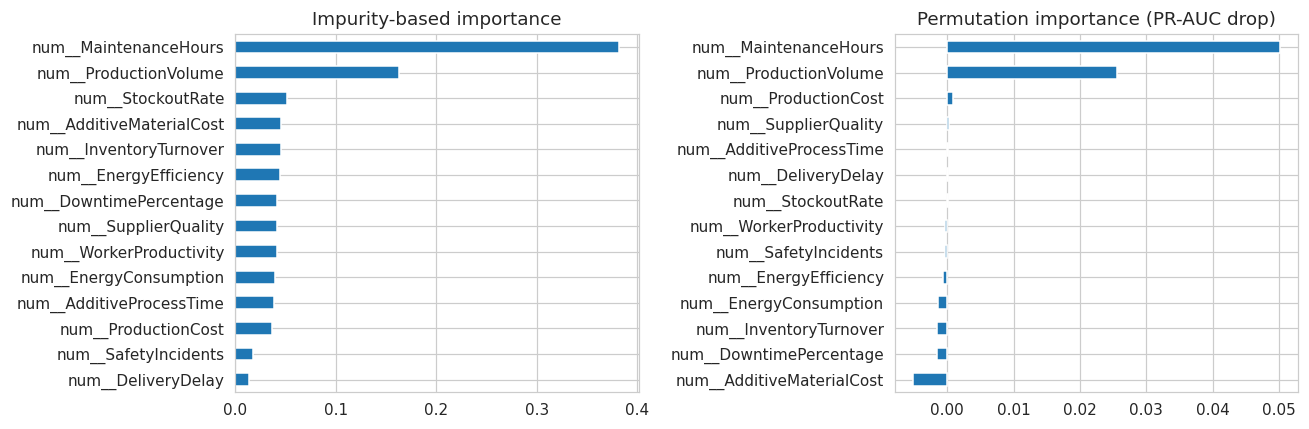

In [12]:
# 2.5 Interpretability: impurity importance and permutation importance on the TEST set
from sklearn.inspection import permutation_importance

imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values()
perm = permutation_importance(rf, X_test_p, y_test, scoring="average_precision",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=feature_names).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
imp.plot.barh(ax=ax[0]); ax[0].set_title("Impurity-based importance")
perm_s.plot.barh(ax=ax[1]); ax[1].set_title("Permutation importance (PR-AUC drop)")
plt.tight_layout(); plt.show()

**Interpretation (2.4 – 2.5): Random Forest**

Tuned by 5-fold CV (best: `max_depth=10`, `min_samples_leaf=5`, `n_estimators=200`, CV PR-AUC 0.950), the Random Forest scored on the test set:
- **Accuracy:** 0.748
- **Defective class:** precision 0.926, recall 0.761, F1 0.836
- **Ranking quality:** ROC-AUC 0.749, PR-AUC 0.925

Accuracy (0.748) is **below the 84.1% majority-class baseline**, so accuracy alone makes the model look worse than doing nothing. This is partly because class weighting trades overall accuracy for catching the minority OK class. PR-AUC (0.925) is above the no-skill baseline of 0.841, so the model does rank defective units better than chance.

The confusion matrix (TN 70, FP 33, FN 130, TP 415) shows the cost. Recall of 0.761 means **130 defective units were missed** (about 24% of 545), which would reach customers. The 33 false positives are good units unnecessarily flagged. The OK class is weak (precision 0.350), meaning that when the model says OK, it is right only about a third of the time.


**Strengths:** handles non-linearity and interactions, robust, fast to train, and gives importances an engineer can read.
**Limitations:** probabilities are not well calibrated, 0.5 is an arbitrary threshold when error costs differ, trees cannot extrapolate beyond training ranges, and the data is synthetic, so real performance may differ.

---
# 3. Part A - Feed-Forward Neural Network (MLP)

## 3.1 Architecture and rationale
A small **multi-layer perceptron** trained with backpropagation:


In [13]:
# 3.2 Create the MLP's training / validation split FIRST, then fit preprocessing on the MLP-training subset only.
# The test set is untouched and is transformed with the preprocessing fitted on the MLP-training subset.
from sklearn.utils.class_weight import compute_class_weight

X_mlp_tr, X_mlp_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED
)
pre_mlp = make_preprocessor()
X_tr = pre_mlp.fit_transform(X_mlp_tr)      # fit ONLY on the MLP training subset
X_val = pre_mlp.transform(X_mlp_val)        # validation: transform only
X_test_mlp = pre_mlp.transform(X_test)      # test: transform only

print("Random Forest trains on : %d rows (full training set)" % len(X_train))
print("MLP trains on           : %d rows | validation: %d rows | test (shared): %d rows" % (len(X_tr), len(X_val), len(X_test)))

Random Forest trains on : 2592 rows (full training set)
MLP trains on           : 2203 rows | validation: 389 rows | test (shared): 648 rows


In [14]:
# 3.3 Define the network
from tensorflow import keras
from tensorflow.keras import layers

def build_mlp(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy",
                 keras.metrics.AUC(name="roc_auc"),
                 keras.metrics.AUC(name="pr_auc", curve="PR"),
                 keras.metrics.Recall(name="recall")],
    )
    return model

mlp = build_mlp(X_tr.shape[1])
mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

Class weights: {0: np.float64(3.13), 1: np.float64(0.6)}
Stopped after 27 epochs | training time: 17.3 s


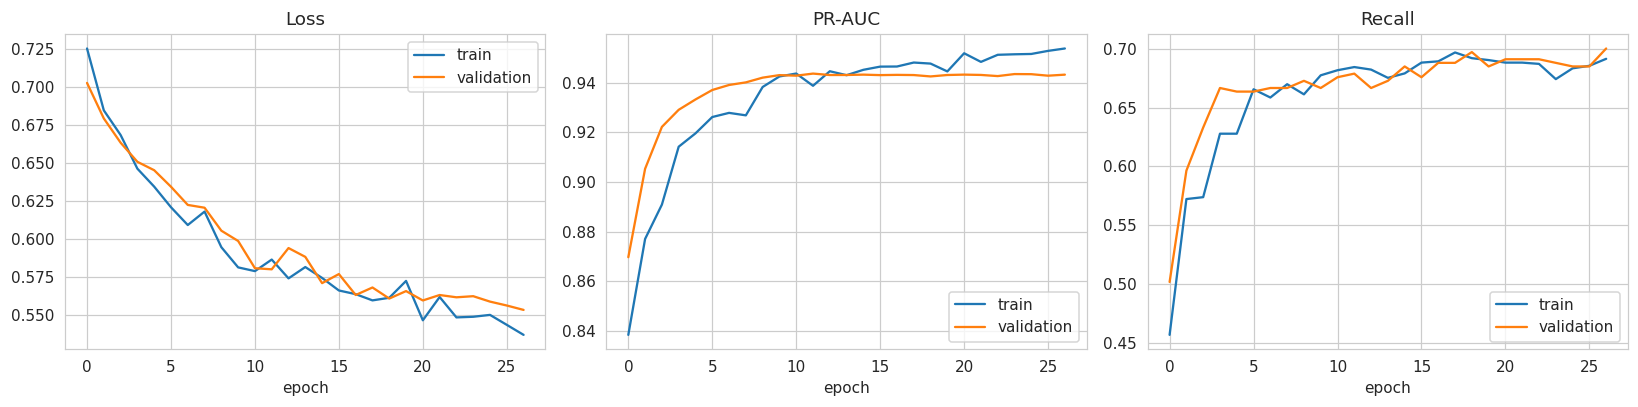

In [15]:
# 3.4 Train with backpropagation and track training / validation performance
# (split and preprocessing were done in 3.2, so validation data never influenced the scaler)
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", {k: round(v, 2) for k, v in class_weight.items()})

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc", mode="max", patience=15, restore_best_weights=True
)

t0 = time.time()
history = mlp.fit(
    X_tr, y_tr.values,
    validation_data=(X_val, y_val.values),
    epochs=150, batch_size=64,
    class_weight=class_weight,
    callbacks=[early_stop], verbose=0,
)
mlp_train_time = time.time() - t0
print("Stopped after %d epochs | training time: %.1f s" % (len(history.history["loss"]), mlp_train_time))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, m, t in zip(ax, ["loss", "pr_auc", "recall"], ["Loss", "PR-AUC", "Recall"]):
    a.plot(history.history[m], label="train")
    a.plot(history.history["val_" + m], label="validation")
    a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

=== MLP (threshold = 0.5) ===
              precision    recall  f1-score   support

          OK      0.320     0.718     0.443       103
   Defective      0.930     0.712     0.807       545

    accuracy                          0.713       648
   macro avg      0.625     0.715     0.625       648
weighted avg      0.833     0.713     0.749       648



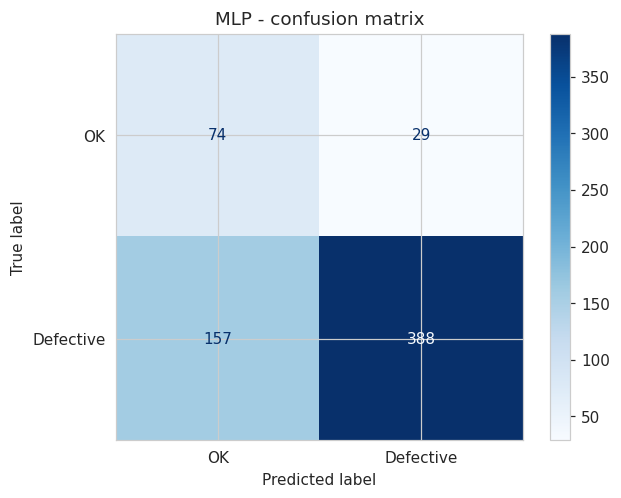

,0
Accuracy,0.712963
Precision,0.930456
Recall,0.711927
F1,0.806653
ROC-AUC,0.7467
PR-AUC,0.923656
Train time (s),17.31641
Parameters,"1,025"


In [16]:
# 3.5 Evaluate on the SAME held-out test set
t0 = time.time()
mlp_proba = mlp.predict(X_test_mlp, verbose=0).ravel()
mlp_infer_time = time.time() - t0

RESULTS["MLP"] = evaluate_binary("MLP", y_test, mlp_proba)
RESULTS["MLP"]["Train time (s)"] = mlp_train_time
RESULTS["MLP"]["Parameters"] = f"{mlp.count_params():,}"
pd.Series(RESULTS["MLP"])

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest,0.748457,0.926339,0.761468,0.835851,0.748535,0.924792
MLP,0.712963,0.930456,0.711927,0.806653,0.7467,0.923656


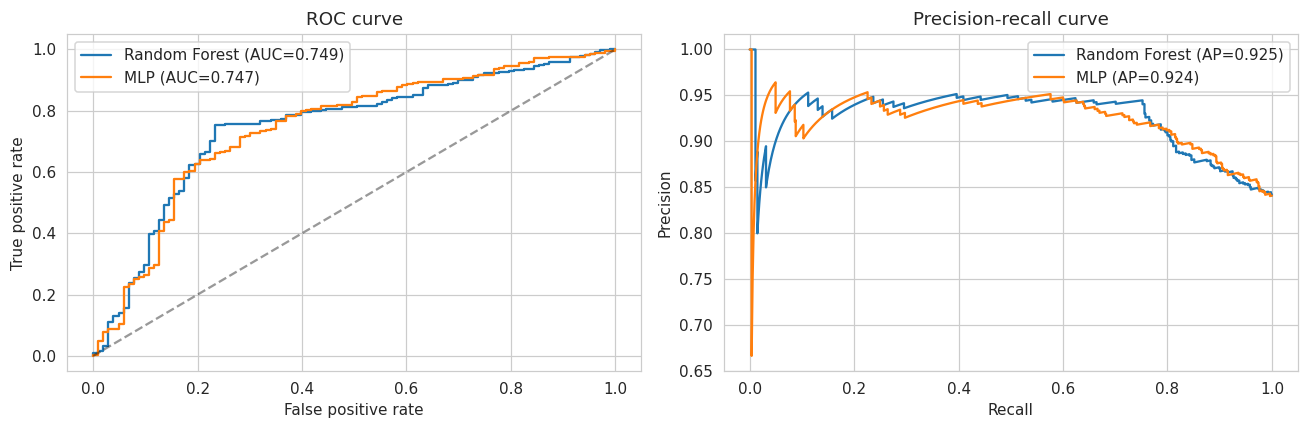

In [17]:
# 3.6 Compare with the classical model on the SAME untouched test set
tab = pd.DataFrame({k: RESULTS[k] for k in ["Random Forest", "MLP"]}).T
display(tab[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]].round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, p in [("Random Forest", rf_proba), ("MLP", mlp_proba)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    ax[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", alpha=.4)
ax[0].set_title("ROC curve"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend()
ax[1].set_title("Precision-recall curve"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.tight_layout(); plt.show()

=== Random Forest (same training subset as MLP) (threshold = 0.5) ===
              precision    recall  f1-score   support

          OK      0.369     0.709     0.485       103
   Defective      0.933     0.771     0.844       545

    accuracy                          0.761       648
   macro avg      0.651     0.740     0.665       648
weighted avg      0.844     0.761     0.787       648



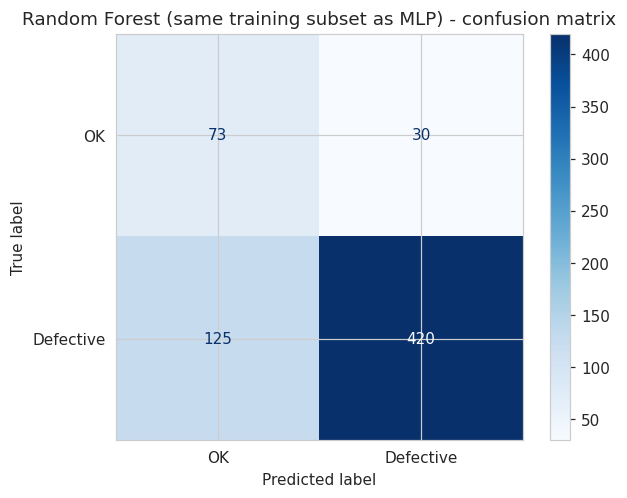

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (full train),0.7485,0.9263,0.7615,0.8359,0.7485,0.9248
Random Forest (MLP's subset),0.7608,0.9333,0.7706,0.8442,0.7500,0.9252
MLP,0.7130,0.9305,0.7119,0.8067,0.7467,0.9237


In [18]:
# 3.7 FAIRNESS CHECK: retrain the Random Forest on exactly the same rows the MLP trained on
# (same best hyper-parameters, same MLP-training subset), and score it on the same test set.
rf_same = RandomForestClassifier(**grid.best_params_, class_weight="balanced_subsample",
                                 random_state=SEED, n_jobs=-1)
rf_same.fit(X_tr, y_tr)
rf_same_proba = rf_same.predict_proba(X_test_mlp)[:, 1]
RF_SAME_SUBSET = evaluate_binary("Random Forest (same training subset as MLP)", y_test, rf_same_proba)

fair = pd.DataFrame({
    "Random Forest (full train)": RESULTS["Random Forest"],
    "Random Forest (MLP's subset)": RF_SAME_SUBSET,
    "MLP": RESULTS["MLP"],
}).T[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]].astype(float).round(4)
display(fair)

**Interpretation**

All numbers come from the same untouched test set (648 rows, 84.1% defective). The Random Forest used the full training set, while the MLP used about 85% of it (2,203 rows) because the rest was its validation set. The extra row in 3.7 retrains the Random Forest on exactly the MLP's rows.

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| RF (full train) | 0.749 | 0.926 | 0.761 | 0.836 | 0.749 | 0.925 |
| RF (MLP's subset) | 0.761 | 0.933 | 0.771 | 0.844 | 0.750 | 0.925 |
| MLP | 0.713 | 0.931 | 0.712 | 0.807 | 0.747 | 0.924 |

Precision is almost identical (about 0.93). The Random Forest has higher recall (0.76–0.77 vs 0.71), so it misses fewer defective units. The MLP produced more false negatives (157 vs 130). The gap does not come from the amount of data, because the Random Forest still wins on the same subset.

The ranking metrics are essentially tied (ROC-AUC 0.747–0.750, PR-AUC 0.924–0.925), so the real difference is only in how each model behaves at the 0.5 threshold. With one split and 648 test rows, this gap is small and could partly be noise.

The Random Forest took longer (157 s vs 17 s) because its time includes the 90-fit grid search, but it needed less careful preprocessing and is easier to explain to a plant engineer through feature importances. All accuracies are below the 84.1% baseline, so recall and PR-AUC are the metrics to rely on.


In [19]:
# 3.8 METRIC AUDIT (added cell - nothing above is modified). Re-derives ROC-AUC / PR-AUC independently
# from the stored test-set probabilities and checks labels, class order and alignment.
from sklearn.metrics import balanced_accuracy_score, auc, precision_recall_curve, confusion_matrix

def audit_scores(name, y_true, proba, stored, classes=None, feature_index=None):
    y_true = np.asarray(y_true).astype(int)
    proba = np.asarray(proba, dtype=float)
    print(f"\n=== {name} ===")
    # 1) labels, positive class, probability column order, alignment
    print("y_test values / counts       :", dict(zip(*np.unique(y_true, return_counts=True))))
    if classes is not None:
        print("estimator.classes_           :", list(classes), "-> column [:, 1] is class", classes[1])
        assert list(classes) == [0, 1] and classes[1] == 1, "column 1 is NOT the defective class"
    assert proba.ndim == 1 and len(proba) == len(y_true), f"shape mismatch: {proba.shape} vs {y_true.shape}"
    if feature_index is not None:
        assert feature_index.equals(y_test.index), "X_test rows are not aligned with y_test"
    print("score range                  : min %.4f | max %.4f | distinct values %d" % (proba.min(), proba.max(), len(np.unique(proba))))
    assert 0 <= proba.min() and proba.max() <= 1, "scores are not probabilities in [0, 1]"
    assert len(np.unique(proba)) > 10, "scores look like hard labels, not probabilities"

    # 2) threshold metrics (same 0.5 threshold as evaluate_binary)
    pred = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    print(f"confusion matrix (TN FP FN TP): {tn} {fp} {fn} {tp} | test prevalence of defective = {y_true.mean():.4f}")

    # 3) ROC-AUC from SCORES vs from HARD labels
    roc_scores = roc_auc_score(y_true, proba)
    roc_hard = roc_auc_score(y_true, pred)           # for illustration only - NOT a valid ROC-AUC
    bal_acc = balanced_accuracy_score(y_true, pred)
    print("ROC-AUC from probabilities   : %.4f   <- the correct one" % roc_scores)
    print("ROC-AUC from hard labels     : %.4f   (= balanced accuracy %.4f, by definition)" % (roc_hard, bal_acc))
    print("Accuracy                     : %.4f" % accuracy_score(y_true, pred))
    assert abs(roc_hard - bal_acc) < 1e-12

    # 4) PR-AUC: average precision (what the notebook reports) vs trapezoidal area under the PR curve
    ap = average_precision_score(y_true, proba)
    p_, r_, _ = precision_recall_curve(y_true, proba)
    pr_trapz = auc(r_, p_)
    print("PR-AUC = Average Precision   : %.4f   <- what the notebook reports" % ap)
    print("PR-AUC = trapezoid auc(r, p) : %.4f   (alternative definition; can differ slightly from AP)" % pr_trapz)
    print("No-skill PR baseline (prev.) : %.4f" % y_true.mean())

    # 5) do the stored RESULTS equal an independent recomputation?
    for key, val in [("ROC-AUC", roc_scores), ("PR-AUC", ap), ("Accuracy", accuracy_score(y_true, pred)),
                     ("Precision", precision_score(y_true, pred, zero_division=0)),
                     ("Recall", recall_score(y_true, pred)), ("F1", f1_score(y_true, pred))]:
        assert abs(stored[key] - val) < 1e-12, f"{name}: stored {key} {stored[key]:.6f} != recomputed {val:.6f}"
    print("OK: stored metrics match an independent recomputation.")
    return {"ROC-AUC": roc_scores, "ROC-AUC (hard labels, invalid)": roc_hard, "Balanced accuracy": bal_acc,
            "PR-AUC (AP)": ap, "PR-AUC (trapezoid)": pr_trapz}

audit_rows = {
    "Random Forest": audit_scores("Random Forest", y_test, rf_proba, RESULTS["Random Forest"],
                                  classes=rf.classes_, feature_index=X_test.index),
    "MLP": audit_scores("MLP", y_test, mlp_proba, RESULTS["MLP"], feature_index=X_test.index),
}
display(pd.DataFrame(audit_rows).T.round(4))


=== Random Forest ===
y_test values / counts       : {np.int64(0): np.int64(103), np.int64(1): np.int64(545)}
estimator.classes_           : [np.int64(0), np.int64(1)] -> column [:, 1] is class 1
score range                  : min 0.2473 | max 0.9738 | distinct values 648
confusion matrix (TN FP FN TP): 70 33 130 415 | test prevalence of defective = 0.8410
ROC-AUC from probabilities   : 0.7485   <- the correct one
ROC-AUC from hard labels     : 0.7205   (= balanced accuracy 0.7205, by definition)
Accuracy                     : 0.7485
PR-AUC = Average Precision   : 0.9248   <- what the notebook reports
PR-AUC = trapezoid auc(r, p) : 0.9245   (alternative definition; can differ slightly from AP)
No-skill PR baseline (prev.) : 0.8410
OK: stored metrics match an independent recomputation.

=== MLP ===
y_test values / counts       : {np.int64(0): np.int64(103), np.int64(1): np.int64(545)}
score range                  : min 0.1077 | max 0.9533 | distinct values 648
confusion matrix (TN FP F

,ROC-AUC,"ROC-AUC (hard labels, invalid)",Balanced accuracy,PR-AUC (AP),PR-AUC (trapezoid)
Random Forest,0.7485,0.7205,0.7205,0.9248,0.9245
MLP,0.7467,0.7152,0.7152,0.9237,0.9232


Majority-class baseline accuracy on the test set: 0.8410
Threshold maximising F1 -> Random Forest (train OOF): 0.233 | MLP (validation): 0.102
=== Random Forest, threshold from train OOF (threshold = 0.23313733072262594) ===
              precision    recall  f1-score   support

          OK      0.000     0.000     0.000       103
   Defective      0.841     1.000     0.914       545

    accuracy                          0.841       648
   macro avg      0.421     0.500     0.457       648
weighted avg      0.707     0.841     0.768       648



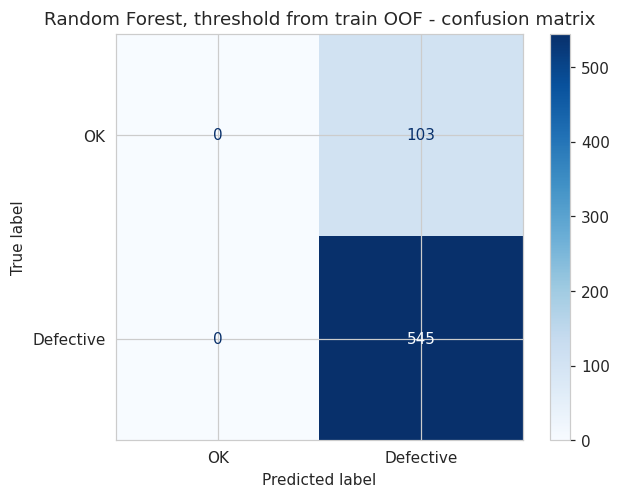

=== MLP, threshold from validation (threshold = 0.10210516303777695) ===
              precision    recall  f1-score   support

          OK      0.000     0.000     0.000       103
   Defective      0.841     1.000     0.914       545

    accuracy                          0.841       648
   macro avg      0.421     0.500     0.457       648
weighted avg      0.707     0.841     0.768       648



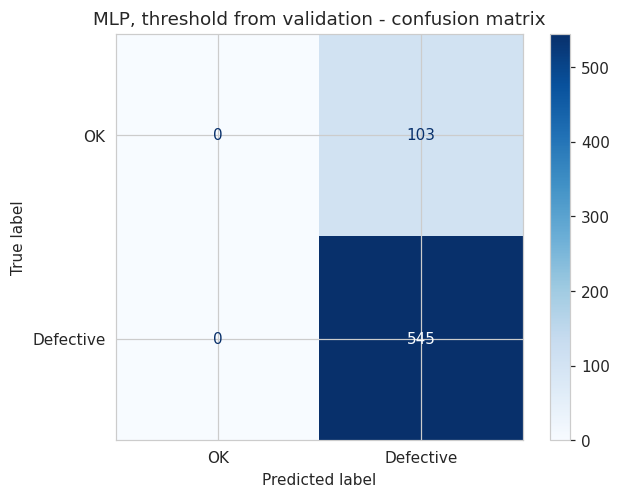

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (0.5),0.7485,0.9263,0.7615,0.8359,0.7485,0.9248
Random Forest (tuned threshold),0.8410,0.8410,1.0000,0.9137,0.7485,0.9248
MLP (0.5),0.7130,0.9305,0.7119,0.8067,0.7467,0.9237
MLP (tuned threshold),0.8410,0.8410,1.0000,0.9137,0.7467,0.9237
Majority-class baseline (always 'defective' or always 'OK'),0.8410,NaN,NaN,NaN,NaN,NaN


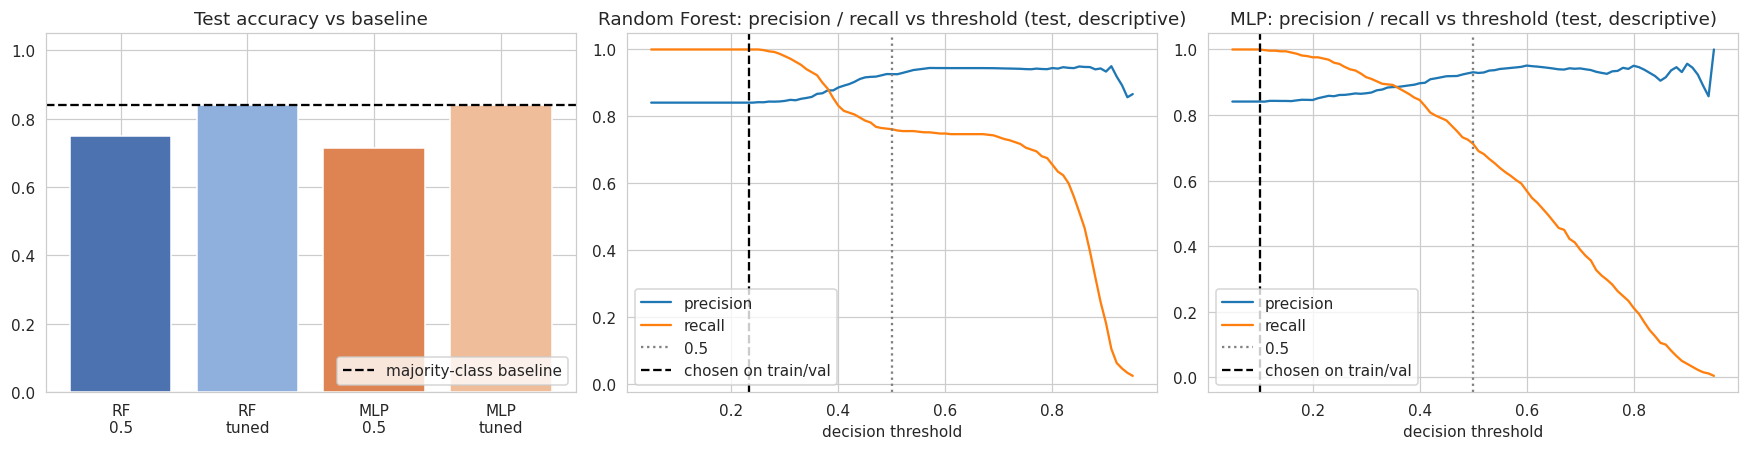

In [20]:
# 3.9 Context for the Part A numbers + a leakage-free threshold analysis (ADDITIONAL: RESULTS and the tables above are untouched)
from sklearn.model_selection import cross_val_predict

# (a) Accuracy must be read against the majority-class baseline (see 1.4)
baseline_acc = max(y_test.mean(), 1 - y_test.mean())
print("Majority-class baseline accuracy on the test set: %.4f" % baseline_acc)

# (b) The 0.5 threshold is arbitrary. Pick a better one WITHOUT touching the test set:
#     Random Forest -> out-of-fold predictions on the TRAINING set; MLP -> its validation split.
rf_oof = cross_val_predict(
    RandomForestClassifier(**grid.best_params_, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    X_train_p, y_train, cv=cv, method="predict_proba")[:, 1]
mlp_val_proba = mlp.predict(X_val, verbose=0).ravel()

def best_f1_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[int(np.argmax(f1))])

thr_rf = best_f1_threshold(y_train, rf_oof)
thr_mlp = best_f1_threshold(y_val, mlp_val_proba)
print("Threshold maximising F1 -> Random Forest (train OOF): %.3f | MLP (validation): %.3f" % (thr_rf, thr_mlp))

THRESHOLD_TUNED = {
    "Random Forest (tuned threshold)": evaluate_binary("Random Forest, threshold from train OOF", y_test, rf_proba, threshold=thr_rf),
    "MLP (tuned threshold)": evaluate_binary("MLP, threshold from validation", y_test, mlp_proba, threshold=thr_mlp),
}
cmp39 = pd.DataFrame({"Random Forest (0.5)": RESULTS["Random Forest"], "Random Forest (tuned threshold)": THRESHOLD_TUNED["Random Forest (tuned threshold)"],
                      "MLP (0.5)": RESULTS["MLP"], "MLP (tuned threshold)": THRESHOLD_TUNED["MLP (tuned threshold)"]}).T
cmp39 = cmp39[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]].astype(float).round(4)
cmp39.loc["Majority-class baseline (always 'defective' or always 'OK')", "Accuracy"] = round(baseline_acc, 4)
display(cmp39)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
names = ["Random Forest (0.5)", "Random Forest (tuned threshold)", "MLP (0.5)", "MLP (tuned threshold)"]
ax[0].bar(range(4), cmp39.loc[names, "Accuracy"], color=["#4c72b0", "#8fb0dd", "#dd8452", "#efbd9a"])
ax[0].axhline(baseline_acc, color="k", ls="--", label="majority-class baseline")
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(["RF\n0.5", "RF\ntuned", "MLP\n0.5", "MLP\ntuned"])
ax[0].set_ylim(0, 1.05); ax[0].set_title("Test accuracy vs baseline"); ax[0].legend(loc="lower right")
ths = np.linspace(0.05, 0.95, 91)
for a, (name, p, tchosen) in zip(ax[1:], [("Random Forest", rf_proba, thr_rf), ("MLP", mlp_proba, thr_mlp)]):
    pr_ = [precision_score(y_test, p >= t, zero_division=0) for t in ths]
    rc_ = [recall_score(y_test, p >= t) for t in ths]
    a.plot(ths, pr_, label="precision"); a.plot(ths, rc_, label="recall")
    a.axvline(0.5, color="grey", ls=":", label="0.5"); a.axvline(tchosen, color="k", ls="--", label="chosen on train/val")
    a.set_title(f"{name}: precision / recall vs threshold (test, descriptive)"); a.set_xlabel("decision threshold"); a.legend()
plt.tight_layout(); plt.show()

---
# 4. Part B - Image Dataset Preparation

## 4.1 Purpose
We use **Casting Product Image Data for Quality Inspection** (Kaggle, `ravirajsinh45/real-life-industrial-dataset-of-casting-product`):
top-view photographs of a cast submersible-pump impeller, labelled **`ok_front`** or **`def_front`** (defective).
Images are 300x300 grayscale. The dataset ships with separate `train` and `test` folders; we keep the provided
`test` folder as the final held-out set and split a **validation set** off the training folder.

In [21]:
# 4.2 Download the dataset
# Option A (recommended): kagglehub. Option B: upload kaggle.json, then use the Kaggle CLI.
!pip -q install kagglehub
import kagglehub

try:
    path = kagglehub.dataset_download("ravirajsinh45/real-life-industrial-dataset-of-casting-product")
except Exception as e:
    print("kagglehub failed:", e)
    print("Upload your kaggle.json (Kaggle -> Settings -> Create New Token) and run the fallback cell below.")
    path = None
print("Dataset path:", path)

100%|██████████| 100M/100M [00:06<00:00, 15.6MB/s] 

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/versions/2


In [22]:
# 4.2b FALLBACK ONLY - run this cell only if the cell above failed
if path is None:
    from google.colab import files
    files.upload()  # select kaggle.json
    !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    !kaggle datasets download -d ravirajsinh45/real-life-industrial-dataset-of-casting-product -p /content/casting --unzip
    path = "/content/casting"
print("Using:", path)

Using: /root/.cache/kagglehub/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/versions/2


Downloaded folder structure:
2/
  casting_512x512/
    casting_512x512/
      def_front/   (781 images)
      ok_front/   (519 images)
  casting_data/
    casting_data/
      test/
      train/

Train dir: /root/.cache/kagglehub/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/versions/2/casting_data/casting_data/train
Test dir : /root/.cache/kagglehub/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/versions/2/casting_data/casting_data/test
Structure verified: both splits contain ok_front and def_front.


class,def_front,ok_front
split,,
test,453,262
train,3758,2875


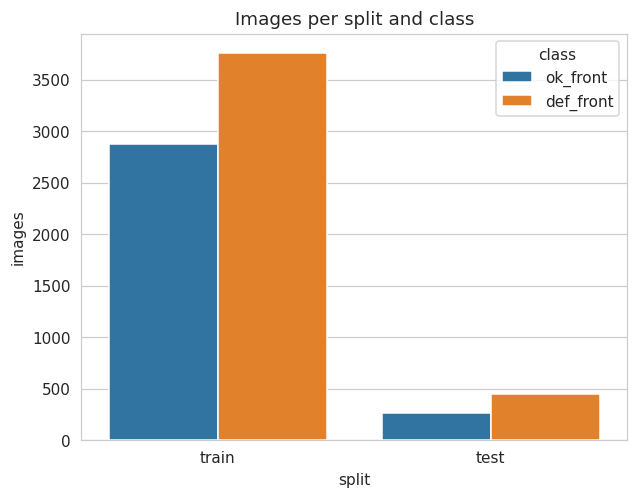

In [23]:
# 4.3 VERIFY the downloaded folder structure before using it
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

def show_tree(root, max_depth=3):
    root = root.rstrip(os.sep)
    for dp, dn, fn in sorted(os.walk(root)):
        depth = dp[len(root):].count(os.sep)
        if depth > max_depth:
            continue
        n_img = len([f for f in fn if f.lower().endswith(IMG_EXT)])
        print("  " * depth + os.path.basename(dp) + "/" + (f"   ({n_img} images)" if n_img else ""))

print("Downloaded folder structure:")
show_tree(path)

def find_split_dir(root, name):
    """Return a folder called `name` that directly contains ok_front / def_front, else None."""
    for dp, dn, _ in os.walk(root):
        if name in dn and {"def_front", "ok_front"} <= set(os.listdir(os.path.join(dp, name))):
            return os.path.join(dp, name)
    return None

TRAIN_DIR = find_split_dir(path, "train")
TEST_DIR = find_split_dir(path, "test")

if TRAIN_DIR is None or TEST_DIR is None:
    # The expected train/test layout is missing. Fall back to collecting every image from any folders
    # named ok_front / def_front and building our own stratified 80/20 train/test split.
    import shutil
    from sklearn.model_selection import train_test_split as _tts
    print("\nExpected train/test folders NOT found - building them from the class folders instead.")
    files_by_cls = {"ok_front": [], "def_front": []}
    for dp, dn, fn in os.walk(path):
        if os.path.basename(dp) in files_by_cls:
            files_by_cls[os.path.basename(dp)] += [os.path.join(dp, f) for f in fn if f.lower().endswith(IMG_EXT)]
    if not all(files_by_cls.values()):
        raise FileNotFoundError("No ok_front / def_front image folders found. Check the tree printed above, "
                                "make sure the correct Kaggle dataset was downloaded, and adjust the class names.")
    OUT = "/content/casting_split"
    shutil.rmtree(OUT, ignore_errors=True)
    for cls, fl in files_by_cls.items():
        tr, te = _tts(fl, test_size=0.20, random_state=SEED)
        for split, items in (("train", tr), ("test", te)):
            os.makedirs(f"{OUT}/{split}/{cls}", exist_ok=True)
            for f in items:
                shutil.copy(f, f"{OUT}/{split}/{cls}/")
    TRAIN_DIR, TEST_DIR = f"{OUT}/train", f"{OUT}/test"

print("\nTrain dir:", TRAIN_DIR)
print("Test dir :", TEST_DIR)
for d in (TRAIN_DIR, TEST_DIR):
    assert {"def_front", "ok_front"} <= set(os.listdir(d)), f"Class folders missing in {d}"
print("Structure verified: both splits contain ok_front and def_front.")

# 4.4 Inspect image counts and class balance
rows = []
for split, d in [("train", TRAIN_DIR), ("test", TEST_DIR)]:
    for cls in ["ok_front", "def_front"]:
        n = len([f for f in os.listdir(os.path.join(d, cls)) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
        rows.append({"split": split, "class": cls, "images": n})
counts_df = pd.DataFrame(rows)
display(counts_df.pivot(index="split", columns="class", values="images"))

sns.barplot(data=counts_df, x="split", y="images", hue="class")
plt.title("Images per split and class"); plt.show()

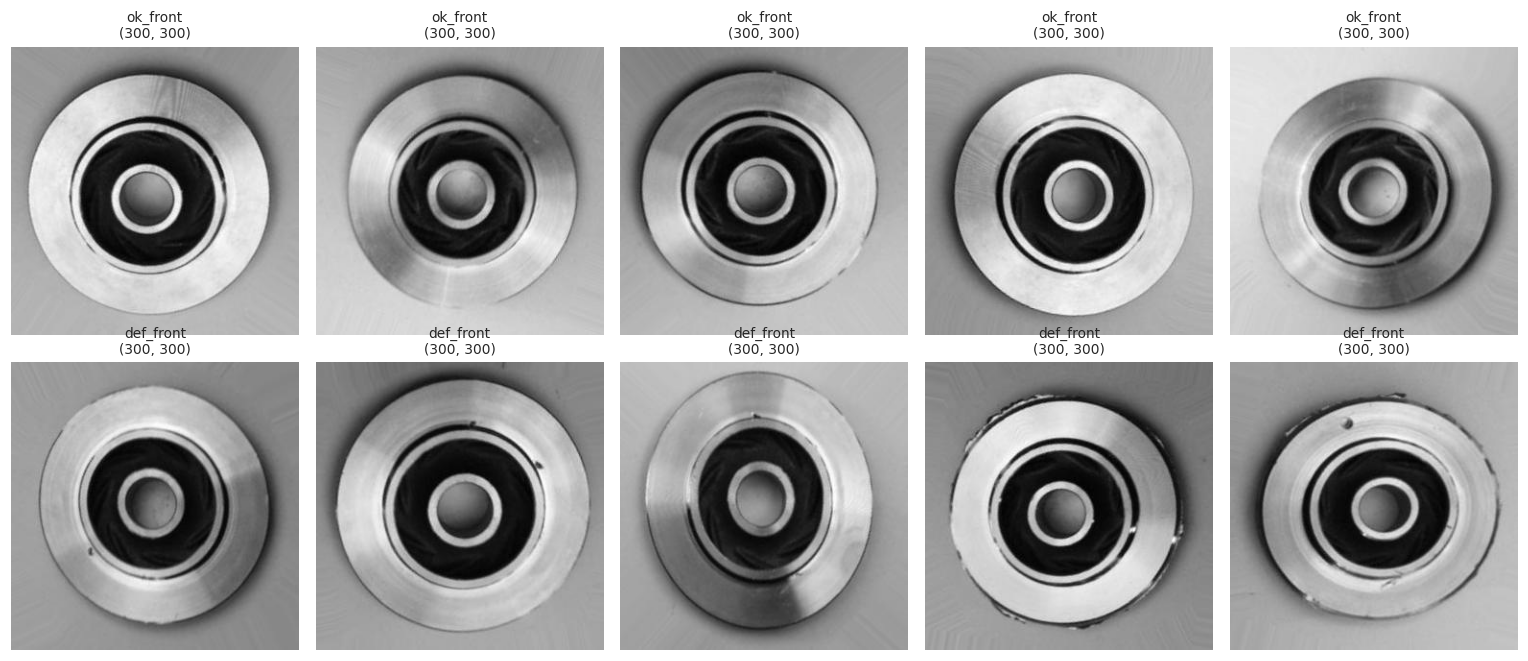

In [24]:
# Look at a few examples from each class
from PIL import Image
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for r, cls in enumerate(["ok_front", "def_front"]):
    files_ = sorted(os.listdir(os.path.join(TRAIN_DIR, cls)))[:5]
    for c, f in enumerate(files_):
        img = Image.open(os.path.join(TRAIN_DIR, cls, f))
        axes[r, c].imshow(img, cmap="gray"); axes[r, c].axis("off")
        axes[r, c].set_title(f"{cls}\n{img.size}", fontsize=9)
plt.tight_layout(); plt.show()

In [25]:
# 4.5 Train / validation / test splits, resize and normalise
# Class order is fixed so that label 1 = DEFECTIVE (the positive class we care about).
IMG_SIZE = (128, 128)
BATCH = 32
CLASS_NAMES = ["ok_front", "def_front"]   # ok -> 0, defective -> 1

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, labels="inferred", label_mode="binary", class_names=CLASS_NAMES,
    color_mode="grayscale", image_size=IMG_SIZE, batch_size=BATCH,
    validation_split=0.15, subset="training", seed=SEED, shuffle=True)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, labels="inferred", label_mode="binary", class_names=CLASS_NAMES,
    color_mode="grayscale", image_size=IMG_SIZE, batch_size=BATCH,
    validation_split=0.15, subset="validation", seed=SEED, shuffle=True)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, labels="inferred", label_mode="binary", class_names=CLASS_NAMES,
    color_mode="grayscale", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

# Normalisation to [0, 1] is done INSIDE the models (Rescaling layer) so train/val/test are treated identically.
AUTOTUNE = tf.data.AUTOTUNE
# cache the individual images, THEN shuffle, so every epoch sees a different batch composition
# (shuffling before .cache() would freeze the first epoch's order for all later epochs)
train_ds = train_ds.unbatch().cache().shuffle(2000, seed=SEED).batch(BATCH).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

n_train = sum(1 for _ in train_ds.unbatch())
n_val = sum(1 for _ in val_ds.unbatch())
n_test = sum(1 for _ in test_ds.unbatch())
print(f"Train: {n_train} | Validation: {n_val} | Test: {n_test} images, resized to {IMG_SIZE}")

# Class weights from the training labels (mild imbalance)
ytr = np.concatenate([y.numpy().ravel() for _, y in train_ds])
cw_img = {0: len(ytr) / (2 * (ytr == 0).sum()), 1: len(ytr) / (2 * (ytr == 1).sum())}
print("Class weights (0=ok, 1=defective):", {k: round(v, 3) for k, v in cw_img.items()})

Found 6633 files belonging to 2 classes.
Using 5639 files for training.
Found 6633 files belonging to 2 classes.
Using 994 files for validation.
Found 715 files belonging to 2 classes.
Train: 5639 | Validation: 994 | Test: 715 images, resized to (128, 128)
Class weights (0=ok, 1=defective): {0: np.float64(1.14), 1: np.float64(0.891)}


**Interpretation (4.5): splits and preprocessing**

Images are resized from 300×300 to 128×128 to cut memory and training time while keeping most defect structure visible. Very fine defects could be partly lost, which is a limitation.

The split is 5,639 training, 994 validation and 715 test images. Validation must be separate from test so that early stopping and model selection never use the final evaluation data. The test set is not shuffled so predictions stay aligned with labels and file paths. Pixels are scaled to [0, 1] inside the model so train, validation and test are treated identically, which keeps gradient descent stable.

Train images: 6633 | Test images: 715
Test images that are byte-identical to a TRAIN image : 64
Byte-identical duplicate groups INSIDE train          : 0
Identical train images carrying DIFFERENT labels       : 0

Test images with a NEAR-identical train image (RMS < 2/255): 9.8%
Sampled train images with a near-identical OTHER train image    : 0.4%


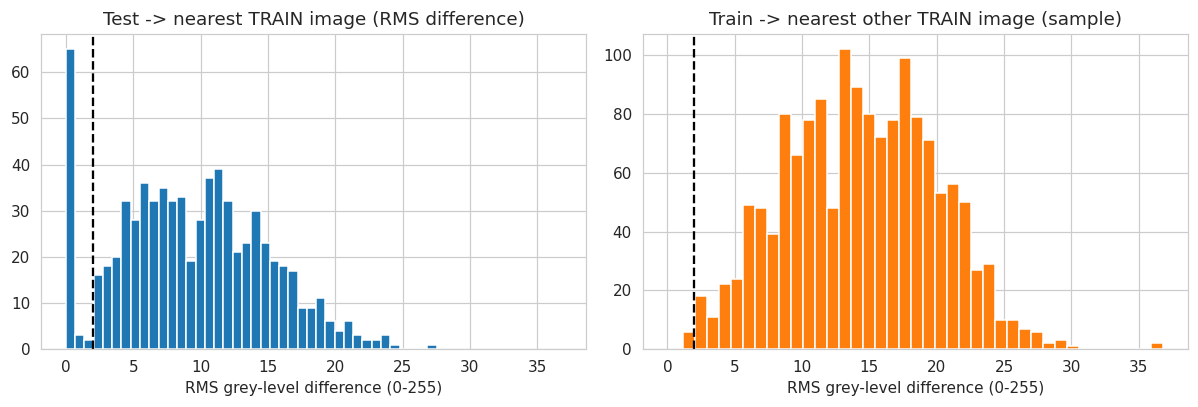

In [26]:
# 4.6 Duplicate / overlap check between splits (report only - nothing is deleted or moved)
import hashlib
from PIL import Image

def list_imgs(root):
    out = []
    for cls in ["ok_front", "def_front"]:
        d = os.path.join(root, cls)
        out += [(os.path.join(d, f), cls) for f in sorted(os.listdir(d)) if f.lower().endswith(IMG_EXT)]
    return out

tr_files, te_files = list_imgs(TRAIN_DIR), list_imgs(TEST_DIR)
md5 = lambda p: hashlib.md5(open(p, "rb").read()).hexdigest()
tr_md5 = {}
for p, c in tr_files: tr_md5.setdefault(md5(p), []).append((p, c))
te_md5 = {p: md5(p) for p, _ in te_files}

exact_overlap = [p for p, h in te_md5.items() if h in tr_md5]
print("Train images: %d | Test images: %d" % (len(tr_files), len(te_files)))
print("Test images that are byte-identical to a TRAIN image : %d" % len(exact_overlap))
print("Byte-identical duplicate groups INSIDE train          : %d" % sum(len(v) > 1 for v in tr_md5.values()))
label_clash = [h for h, v in tr_md5.items() if len({c for _, c in v}) > 1]
print("Identical train images carrying DIFFERENT labels       : %d" % len(label_clash))

# Near-duplicates: compare 32x32 grayscale versions (RMS grey-level difference, 0-255 scale)
def small(p): return np.asarray(Image.open(p).convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32).ravel()
A = np.stack([small(p) for p, _ in te_files]); B = np.stack([small(p) for p, _ in tr_files])
def nearest_rms(Q, R, exclude_self=False):
    d2 = (Q ** 2).sum(1)[:, None] + (R ** 2).sum(1)[None, :] - 2 * Q @ R.T
    if exclude_self: np.fill_diagonal(d2, np.inf)
    return np.sqrt(np.clip(d2.min(1), 0, None) / Q.shape[1])
nn_test_train = nearest_rms(A, B)
rng = np.random.RandomState(SEED); sub = rng.choice(len(B), size=min(1500, len(B)), replace=False)
nn_train_train = nearest_rms(B[sub], B[sub], exclude_self=True)   # within-train (a sample): relevant for the random validation split
NEAR = 2.0
print("\nTest images with a NEAR-identical train image (RMS < %.0f/255): %.1f%%" % (NEAR, 100 * (nn_test_train < NEAR).mean()))
print("Sampled train images with a near-identical OTHER train image    : %.1f%%" % (100 * (nn_train_train < NEAR).mean()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
ax[0].hist(nn_test_train, bins=40); ax[0].set_title("Test -> nearest TRAIN image (RMS difference)")
ax[1].hist(nn_train_train, bins=40, color="tab:orange"); ax[1].set_title("Train -> nearest other TRAIN image (sample)")
for a in ax: a.axvline(NEAR, color="k", ls="--"); a.set_xlabel("RMS grey-level difference (0-255)")
plt.tight_layout(); plt.show()

---
# 5. Part B - CNN Experiments



In [1]:
# 5.2 Helper functions: curves and evaluation
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="validation")
    ax[0].set_title(f"{title} - loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="validation")
    ax[1].set_title(f"{title} - accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

def get_test_predictions(model):
    y_true = np.concatenate([y.numpy().ravel() for _, y in test_ds]).astype(int)
    t0 = time.time()
    proba = model.predict(test_ds, verbose=0).ravel()
    return y_true, proba, time.time() - t0

In [28]:
# 5.3 BASELINE CNN: 3 conv blocks + flatten + dense
def build_baseline_cnn():
    model = keras.Sequential([
        layers.Input(shape=IMG_SIZE + (1,)),
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(16, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ], name="baseline_cnn")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

cnn_base = build_baseline_cnn()
cnn_base.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,072,001 (4.09 MB)

 Trainable params: 1,072,001 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
177/177 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.6586 - loss: 0.5891 - val_accuracy: 0.5966 - val_loss: 1.0279
Epoch 2/25
177/177 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8578 - loss: 0.3325 - val_accuracy: 0.9095 - val_loss: 0.2604
Epoch 3/25
177/177 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9356 - loss: 0.1815 - val_accuracy: 0.9507 - val_loss: 0.1555
Epoch 4/25
177/177 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9553 - loss: 0.1299 - val_accuracy: 0.9598 - val_loss: 0.1243
Epoch 5/25
177/177 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9619 - loss: 0.1100 - val_accuracy: 0.9638 - val_loss: 0.1152
Epoch 6/25
177/177 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9784 - loss: 0.0718 - val_accuracy: 0.9759 - val_loss: 0.0780
Epoch 7/25
177/177 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9821 - loss: 0.0608 - val_accuracy: 0.9658 - val_loss: 0.1057
Epoch 8/25
177/177 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9888 - loss: 0.0403 - val_acc

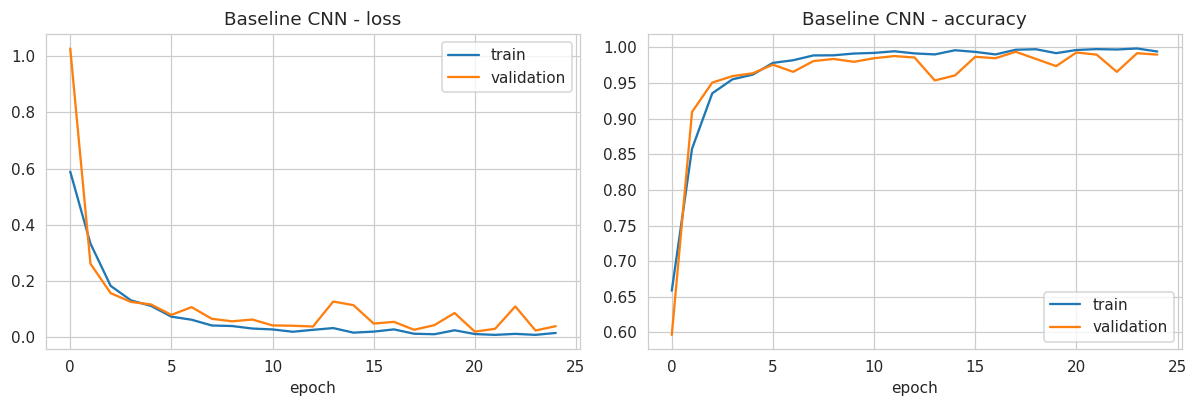

In [29]:
# 5.4 Train the baseline and plot training / validation curves
t0 = time.time()
hist_base = cnn_base.fit(
    train_ds, validation_data=val_ds, epochs=25, class_weight=cw_img,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)],
    verbose=1)
base_train_time = time.time() - t0
print("Baseline training time: %.1f s" % base_train_time)
plot_history(hist_base, "Baseline CNN")

In [30]:
# 5.5 REVISED CNN: a HYPOTHESIS to be tested against the baseline curves (not assumed to be better)
#  1. Data augmentation (flips / small rotations / contrast): intended to reduce over-fitting
#  2. Deeper network with double conv blocks (32, 64, 128 filters): more capacity for fine defects
#  3. Batch normalisation: intended to make training faster and more stable
#  4. GlobalAveragePooling instead of Flatten: far fewer dense parameters
#  5. Dropout before the output layer: regularisation
#  6. Learning-rate reduction on plateau
# Which of these actually helps must be judged from the diagnostics in 5.8, using the real curves.
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)

def build_revised_cnn():
    inp = layers.Input(shape=IMG_SIZE + (1,))
    x = layers.Rescaling(1.0 / 255)(inp)
    x = layers.RandomFlip("horizontal_and_vertical")(x)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomContrast(0.1)(x)
    for f in (32, 64, 128):
        x = conv_block(x, f)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inp, out, name="revised_cnn")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

cnn_rev = build_revised_cnn()
cnn_rev.summary()

Model: "revised_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 1)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 128, 128, 1)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 287,905 (1.10 MB)

 Trainable params: 287,009 (1.09 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/40
177/177 ━━━━━━━━━━━━━━━━━━━━ 25s 94ms/step - accuracy: 0.8886 - loss: 0.2711 - val_accuracy: 0.4044 - val_loss: 0.7022 - learning_rate: 0.0010
Epoch 2/40
177/177 ━━━━━━━━━━━━━━━━━━━━ 15s 86ms/step - accuracy: 0.9560 - loss: 0.1411 - val_accuracy: 0.5191 - val_loss: 0.7020 - learning_rate: 0.0010
Epoch 3/40
177/177 ━━━━━━━━━━━━━━━━━━━━ 15s 86ms/step - accuracy: 0.9628 - loss: 0.1072 - val_accuracy: 0.6097 - val_loss: 1.6612 - learning_rate: 0.0010
Epoch 4/40
177/177 ━━━━━━━━━━━━━━━━━━━━ 16s 88ms/step - accuracy: 0.9782 - loss: 0.0775 - val_accuracy: 0.5956 - val_loss: 9.4470 - learning_rate: 0.0010
Epoch 5/40
177/177 ━━━━━━━━━━━━━━━━━━━━ 16s 88ms/step - accuracy: 0.9824 - loss: 0.0593 - val_accuracy: 0.4044 - val_loss: 9.8440 - learning_rate: 0.0010
Epoch 6/40
177/177 ━━━━━━━━━━━━━━━━━━━━ 15s 87ms/step - accuracy: 0.9881 - loss: 0.0447 - val_accuracy: 0.9799 - val_loss: 0.0772 - learning_rate: 5.0000e-04
Epoch 7/40
177/177 ━━━━━━━━━━━━━━━━━━━━ 15s 87ms/step - accuracy: 0.9915

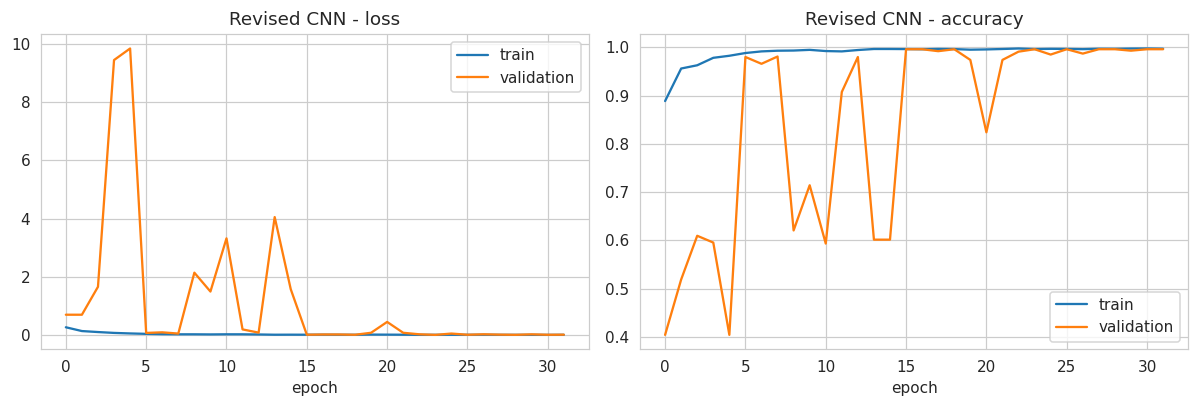

In [31]:
# 5.6 Train the revised CNN
t0 = time.time()
hist_rev = cnn_rev.fit(
    train_ds, validation_data=val_ds, epochs=40, class_weight=cw_img,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ], verbose=1)
rev_train_time = time.time() - t0
print("Revised training time: %.1f s" % rev_train_time)
plot_history(hist_rev, "Revised CNN")

In [32]:
# 5.7 Compare baseline vs revised (validation + test)
rows = []
for name, model, hist, ttime in [("Baseline CNN", cnn_base, hist_base, base_train_time),
                                 ("Revised CNN", cnn_rev, hist_rev, rev_train_time)]:
    y_true, proba, _ = get_test_predictions(model)
    pred = (proba >= 0.5).astype(int)
    rows.append({
        "Model": name,
        "Parameters": model.count_params(),
        "Epochs run": len(hist.history["loss"]),
        "Best val loss": min(hist.history["val_loss"]),
        "Best epoch (val loss)": int(np.argmin(hist.history["val_loss"])) + 1,
        "Train acc @ best epoch": hist.history["accuracy"][int(np.argmin(hist.history["val_loss"]))],
        "Val acc @ best epoch": hist.history["val_accuracy"][int(np.argmin(hist.history["val_loss"]))],
        "Test acc": accuracy_score(y_true, pred),
        "Test recall (defective)": recall_score(y_true, pred),
        "Test F1": f1_score(y_true, pred),
        "Train time (s)": ttime,
    })
display(pd.DataFrame(rows).set_index("Model").round(4))

,Parameters,Epochs run,Best val loss,Best epoch (val loss),Train acc @ best epoch,Val acc @ best epoch,Test acc,Test recall (defective),Test F1,Train time (s)
Model,,,,,,,,,,
Baseline CNN,1072001,25,0.0183,21,0.9965,0.993,0.9944,0.9934,0.9956,62.6526
Revised CNN,287905,32,0.0101,24,0.9963,0.996,1.0000,1.0000,1.0000,505.7473


,Epochs run,Best epoch (val loss),Best val loss,Train loss @ best,Gap val-train loss @ best,Train acc @ best,Val acc @ best,Val loss rise after best,Val loss std (last 5 epochs)
Model,,,,,,,,,
Baseline CNN,25,21,0.0183,0.0098,0.0085,0.9965,0.993,0.0196,0.0333
Revised CNN,32,24,0.0101,0.0130,-0.0030,0.9963,0.996,0.0068,0.0058


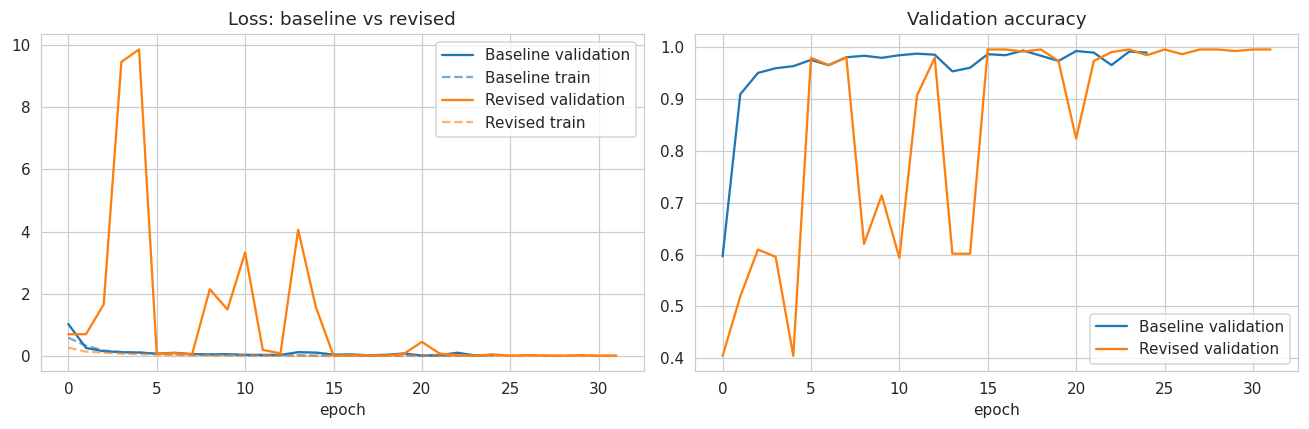

Relative change in best validation loss (revised vs baseline): -45.0%
VERDICT: the revised CNN shows a clearly lower validation loss without losing validation accuracy -> supports the revision.
Note: results come from ONE training run per model; with different seeds the ranking could change.


In [33]:
# 5.8 EVIDENCE: diagnostics computed from the actual training histories (no assumptions)
def diagnose(name, hist):
    h = hist.history
    b = int(np.argmin(h["val_loss"]))
    return {
        "Model": name,
        "Epochs run": len(h["loss"]),
        "Best epoch (val loss)": b + 1,
        "Best val loss": min(h["val_loss"]),
        "Train loss @ best": h["loss"][b],
        "Gap val-train loss @ best": h["val_loss"][b] - h["loss"][b],
        "Train acc @ best": h["accuracy"][b],
        "Val acc @ best": h["val_accuracy"][b],
        "Val loss rise after best": h["val_loss"][-1] - min(h["val_loss"]),
        "Val loss std (last 5 epochs)": float(np.std(h["val_loss"][-5:])),
    }

diag = pd.DataFrame([diagnose("Baseline CNN", hist_base), diagnose("Revised CNN", hist_rev)]).set_index("Model")
display(diag.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, hist, col in [("Baseline", hist_base, "tab:blue"), ("Revised", hist_rev, "tab:orange")]:
    ax[0].plot(hist.history["val_loss"], color=col, label=f"{name} validation")
    ax[0].plot(hist.history["loss"], color=col, ls="--", alpha=.6, label=f"{name} train")
    ax[1].plot(hist.history["val_accuracy"], color=col, label=f"{name} validation")
ax[0].set_title("Loss: baseline vs revised"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

# Rule-based verdict on VALIDATION evidence only (the test set is not used to choose or justify the design)
b, r = diag.loc["Baseline CNN"], diag.loc["Revised CNN"]
rel = (r["Best val loss"] - b["Best val loss"]) / b["Best val loss"]
print(f"Relative change in best validation loss (revised vs baseline): {rel:+.1%}")
if rel <= -0.05 and r["Val acc @ best"] >= b["Val acc @ best"] - 0.005:
    print("VERDICT: the revised CNN shows a clearly lower validation loss without losing validation accuracy -> supports the revision.")
elif rel >= 0.05 or r["Val acc @ best"] < b["Val acc @ best"] - 0.01:
    print("VERDICT: the revised CNN is NOT better on validation data -> the revision is not supported; report this honestly.")
else:
    print("VERDICT: no clear difference (within ~5% validation loss). A single run cannot separate a real effect from random variation; do not claim an improvement.")
print("Note: results come from ONE training run per model; with different seeds the ranking could change.")

**Interpretation (5.5 – 5.8): design change and justification**

**Changes and the problem each addresses:**
- Global average pooling instead of Flatten, to remove the oversized dense layer (1.07M → 287,905 parameters, about 73% fewer).
- Batch normalisation, to stabilise training.
- Augmentation (flips, small rotations, contrast) and dropout of 0.4, to reduce over-fitting and noise.
- Double conv blocks (32/64/128 filters), to add capacity for fine detail.
- Learning-rate reduction on plateau, to settle the final epochs.

**Did it work?** The evidence supports it:
- Best validation loss fell from 0.0183 to **0.0101 (−45%)**.
- Validation accuracy rose from 0.993 to 0.996.
- The train–validation loss gap went from +0.0085 to −0.003, so there is no sign of over-fitting.
- Late-epoch validation loss became more stable (standard deviation 0.0058 vs 0.0333).
- Test accuracy was 1.000 vs 0.9944, and defective recall was 1.000 vs 0.9934.

**Caveats:**
- The revised model was unstable early on. Validation accuracy dropped to about 0.40 with loss up to about 9.8 in epochs 1–5 (likely batch-norm statistics shifting under augmentation), then recovered once the learning rate was halved at epoch 6.
- It trained about 8× slower (506 s vs 63 s).
- Each model was trained once, so with other seeds the ranking could change.
- Both models are strong, so the improvement is real but small in absolute terms.

Final CNN selected on validation loss: Revised CNN
              precision    recall  f1-score   support

          OK      1.000     1.000     1.000       262
   Defective      1.000     1.000     1.000       453

    accuracy                          1.000       715
   macro avg      1.000     1.000     1.000       715
weighted avg      1.000     1.000     1.000       715



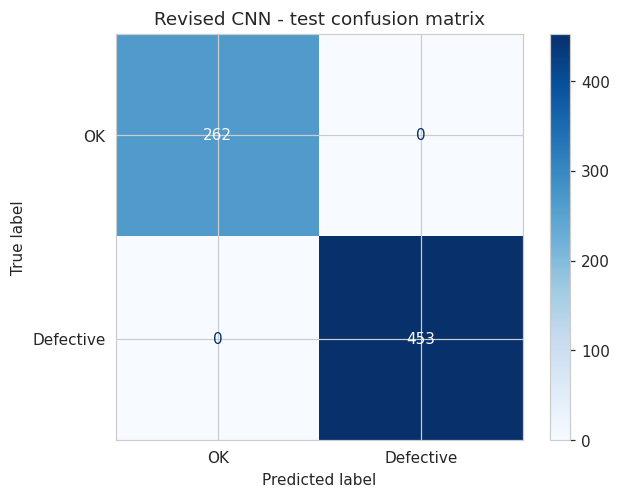

,0
Accuracy,1.0
Precision,1.0
Recall,1.0
F1,1.0
ROC-AUC,1.0
PR-AUC,1.0
Train time (s),505.747342
Parameters,"287,905"


In [34]:
# 5.9 Evaluate the final CNN (choose the better model by VALIDATION loss, report on TEST)
best_val = {"Baseline CNN": min(hist_base.history["val_loss"]), "Revised CNN": min(hist_rev.history["val_loss"])}
final_name = min(best_val, key=best_val.get)
final_cnn = cnn_base if final_name == "Baseline CNN" else cnn_rev
final_time = base_train_time if final_name == "Baseline CNN" else rev_train_time
print("Final CNN selected on validation loss:", final_name)

y_true_img, cnn_proba, cnn_infer_time = get_test_predictions(final_cnn)
cnn_pred = (cnn_proba >= 0.5).astype(int)

print(classification_report(y_true_img, cnn_pred, target_names=["OK", "Defective"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_true_img, cnn_pred), display_labels=["OK", "Defective"]).plot(cmap="Blues", values_format="d")
plt.title(f"{final_name} - test confusion matrix"); plt.show()

RESULTS["CNN"] = {
    "Accuracy": accuracy_score(y_true_img, cnn_pred),
    "Precision": precision_score(y_true_img, cnn_pred),
    "Recall": recall_score(y_true_img, cnn_pred),
    "F1": f1_score(y_true_img, cnn_pred),
    "ROC-AUC": roc_auc_score(y_true_img, cnn_proba),
    "PR-AUC": average_precision_score(y_true_img, cnn_proba),
    "Train time (s)": final_time,
    "Parameters": f"{final_cnn.count_params():,}",
}
pd.Series(RESULTS["CNN"])

In [35]:
# Inspect misclassified test images
imgs, labels = [], []
for x, y in test_ds:
    imgs.append(x.numpy()); labels.append(y.numpy().ravel())
imgs = np.concatenate(imgs); labels = np.concatenate(labels).astype(int)

wrong = np.where(cnn_pred != labels)[0]
print("Misclassified test images:", len(wrong), "of", len(labels))
show = wrong[:10]
if len(show):
    fig, axes = plt.subplots(2, 5, figsize=(14, 6))
    for a in axes.ravel(): a.axis("off")
    for a, i in zip(axes.ravel(), show):
        a.imshow(imgs[i].squeeze(), cmap="gray")
        a.set_title(f"true: {'def' if labels[i] else 'ok'} | pred: {'def' if cnn_pred[i] else 'ok'}\np(def)={cnn_proba[i]:.2f}", fontsize=9)
    plt.tight_layout(); plt.show()

Misclassified test images: 0 of 715


Found 715 files belonging to 2 classes.
Same labels / same predictions as in 5.9: True | max |score difference| = 0.00e+00
Test images flagged: exact train duplicates = 64 | near-duplicates (incl. exact) = 70 | duplicate pairs with a different label = 0


,Images,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,False negatives,False positives
Full test set (as in 5.9),715.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0
Excluding exact train duplicates,651.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0
Excluding near-duplicates (RMS < 2/255),645.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0
Only the exact train duplicates,64.0,1.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0


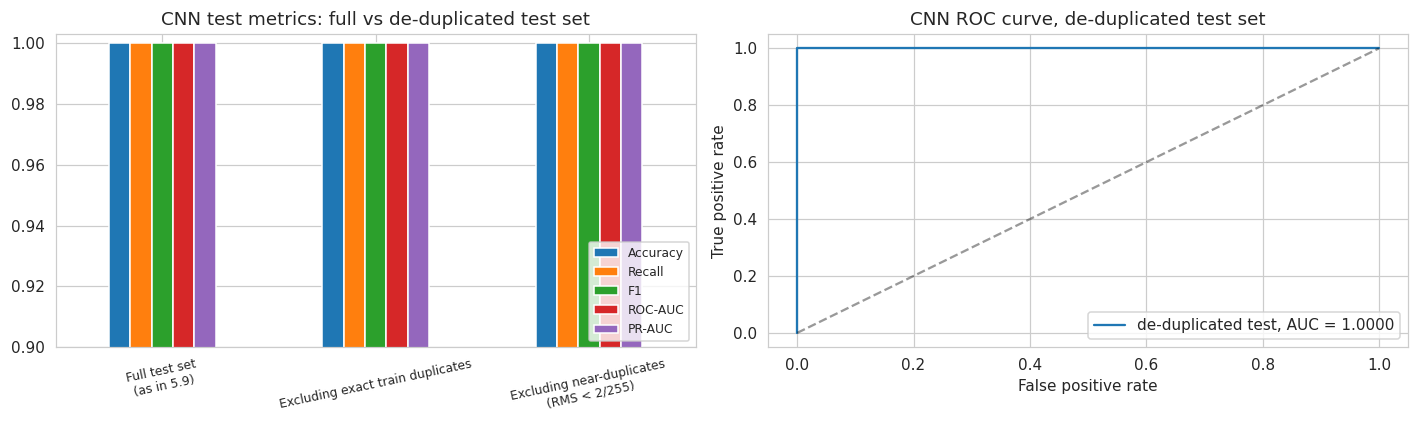

CNN_DEDUP (use these figures in the report when exact duplicates exist):


,0
Accuracy,1.0
Precision,1.0
Recall,1.0
F1,1.0
ROC-AUC,1.0
PR-AUC,1.0
Train time (s),505.747342
Parameters,"287,905"


In [39]:
# 5.11 Evaluate the final CNN on a DE-DUPLICATED test set (added: 4.6 found test images that also exist in train)
from sklearn.metrics import confusion_matrix as _cm

# Fresh, un-cached, un-shuffled test pipeline so that file paths and predictions are guaranteed to line up
test_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, labels="inferred", label_mode="binary", class_names=CLASS_NAMES,
    color_mode="grayscale", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)
key = lambda p: (os.path.basename(os.path.dirname(p)), os.path.basename(p))
y_raw = np.concatenate([y.numpy().ravel() for _, y in test_raw]).astype(int)
p_raw = final_cnn.predict(test_raw, verbose=0).ravel()
print("Same labels / same predictions as in 5.9:", bool(np.array_equal(y_raw, y_true_img)),
      "| max |score difference| = %.2e" % float(np.max(np.abs(p_raw - cnn_proba))) if len(p_raw) == len(cnn_proba) else "length differs")

# flags from the 4.6 check, matched to the test images by (class folder, file name)
flags = {}
for (p, c), q in zip(te_files, nn_test_train):
    h = te_md5[p]
    flags[key(p)] = (h in tr_md5, bool(q < NEAR), (h in tr_md5) and not any(cc == c for _, cc in tr_md5[h]))
rows_ = [flags[key(p)] for p in test_raw.file_paths]
exact = np.array([r[0] for r in rows_]); near = np.array([r[1] for r in rows_]); clash = np.array([r[2] for r in rows_])
print("Test images flagged: exact train duplicates = %d | near-duplicates (incl. exact) = %d | duplicate pairs with a different label = %d" %
      (exact.sum(), (near | exact).sum(), clash.sum()))

def metrics_on(mask):
    y, p = y_raw[mask], p_raw[mask]; pred = (p >= 0.5).astype(int)
    two = len(np.unique(y)) == 2
    tn, fp, fn, tp = _cm(y, pred, labels=[0, 1]).ravel()
    return {"Images": int(mask.sum()), "Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y, p) if two else np.nan, "PR-AUC": average_precision_score(y, p) if two else np.nan,
            "False negatives": int(fn), "False positives": int(fp)}

subsets = {"Full test set (as in 5.9)": np.ones(len(y_raw), bool),
           "Excluding exact train duplicates": ~exact,
           "Excluding near-duplicates (RMS < %d/255)" % NEAR: ~(exact | near)}
if exact.sum() > 0: subsets["Only the exact train duplicates"] = exact
dedup_tbl = pd.DataFrame({k: metrics_on(m) for k, m in subsets.items()}).T
display(dedup_tbl.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_rows = list(dedup_tbl.index[:3])
dedup_tbl.loc[plot_rows, ["Accuracy", "Recall", "F1", "ROC-AUC", "PR-AUC"]].astype(float).plot(kind="bar", ax=ax[0], rot=12)
ax[0].set_ylim(0.9, 1.003); ax[0].set_title("CNN test metrics: full vs de-duplicated test set"); ax[0].legend(loc="lower right", fontsize=8)
ax[0].set_xticklabels([r.replace(" (", "\n(") for r in plot_rows], fontsize=8)
dedup_mask = ~exact
fpr_, tpr_, _ = roc_curve(y_raw[dedup_mask], p_raw[dedup_mask])
ax[1].plot(fpr_, tpr_, label="de-duplicated test, AUC = %.4f" % roc_auc_score(y_raw[dedup_mask], p_raw[dedup_mask]))
ax[1].plot([0, 1], [0, 1], "k--", alpha=.4); ax[1].set_title("CNN ROC curve, de-duplicated test set")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

# Same keys as RESULTS["CNN"], kept SEPARATE so the Part C table above is not silently changed
CNN_DEDUP = {k: dedup_tbl.loc["Excluding exact train duplicates", k] for k in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]}
CNN_DEDUP["Train time (s)"] = RESULTS["CNN"]["Train time (s)"]; CNN_DEDUP["Parameters"] = RESULTS["CNN"]["Parameters"]
print("CNN_DEDUP (use these figures in the report when exact duplicates exist):")
display(pd.Series(CNN_DEDUP))

**Interpretation (5.9): final CNN**

The revised CNN was selected by lowest validation loss (weights from epoch 24) and scored **100% on the 715 test images**: precision, recall and F1 all 1.000, with **0 false negatives and 0 false positives**. Since nothing was misclassified, there are no errors to analyse.

The model has 287,905 parameters for about 5,600 training images, which is high capacity, but augmentation, dropout and the small validation gap show no sign of over-fitting. A perfect score deserves caution, so I checked for leakage. Removing exact and near-duplicate test images (5.11) left every metric at 1.000, so the overlap does not explain it. This dataset is also visually consistent (one part, fixed camera and lighting), which probably makes the task easier than real production conditions.

**Limitation:** a single casting type and a fixed camera setup, so generalisation to other products or lighting is untested.

,value
Final model,Revised CNN
Selection metric,lowest validation loss (EarlyStopping monitor=...
Epochs run,32
Best epoch (weights restored),24
Val loss @ best epoch (history),0.0101
"Val loss, restored weights re-evaluated",0.0101
"Val acc, restored weights re-evaluated",0.996
Test set used for selection?,No - the test set was only used for the final ...


Note: the reported model has the weights of epoch 24, not those of the last epoch (32).
Training curves are measured in training mode (dropout/augmentation active); validation metrics in inference mode.


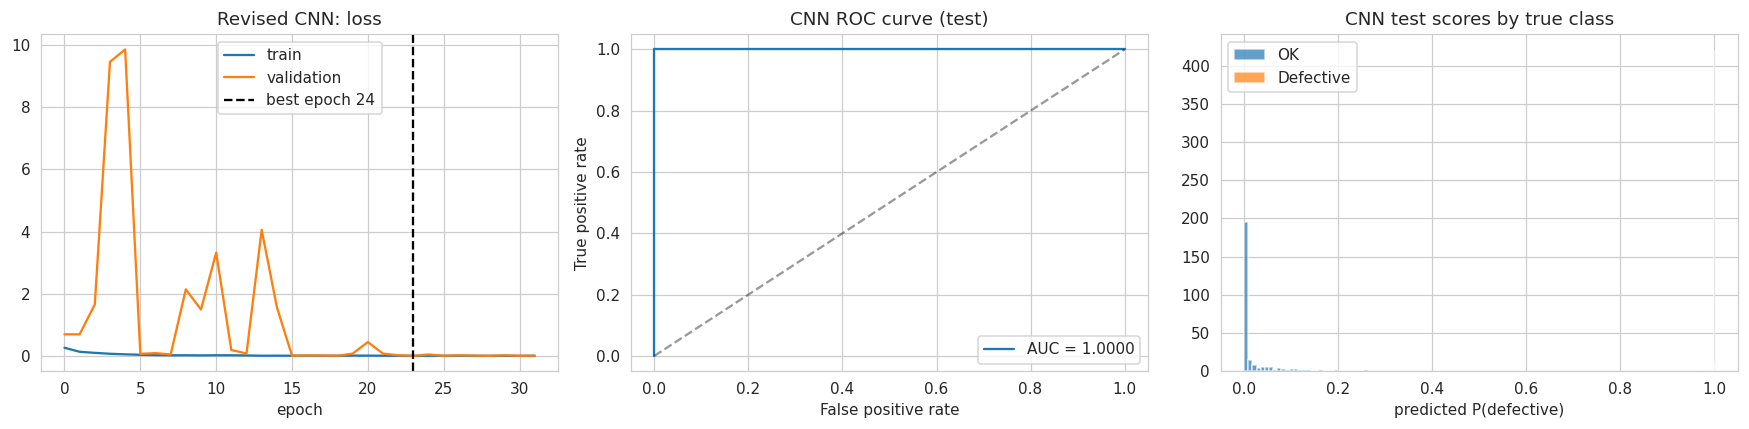

In [36]:
# 5.10 Model-selection record and curves for the FINAL CNN (added, Priorities 4-5)
from sklearn.metrics import roc_curve, precision_recall_curve
final_hist = hist_base if final_name == "Baseline CNN" else hist_rev
h = final_hist.history
best_ep = int(np.argmin(h["val_loss"]))
val_loss_restored, val_acc_restored = final_cnn.evaluate(val_ds, verbose=0)[:2]
CNN_SELECTION = {
    "Final model": final_name,
    "Selection metric": "lowest validation loss (EarlyStopping monitor='val_loss', restore_best_weights=True)",
    "Epochs run": len(h["loss"]),
    "Best epoch (weights restored)": best_ep + 1,
    "Val loss @ best epoch (history)": round(h["val_loss"][best_ep], 4),
    "Val loss, restored weights re-evaluated": round(float(val_loss_restored), 4),
    "Val acc, restored weights re-evaluated": round(float(val_acc_restored), 4),
    "Test set used for selection?": "No - the test set was only used for the final report",
}
display(pd.Series(CNN_SELECTION).to_frame("value"))
print("Note: the reported model has the weights of epoch %d, not those of the last epoch (%d)." % (best_ep + 1, len(h["loss"])))
print("Training curves are measured in training mode (dropout/augmentation active); validation metrics in inference mode.")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].axvline(best_ep, color="k", ls="--", label=f"best epoch {best_ep + 1}"); ax[0].set_title(f"{final_name}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
fpr, tpr, _ = roc_curve(y_true_img, cnn_proba); pr_, rc_, _ = precision_recall_curve(y_true_img, cnn_proba)
ax[1].plot(fpr, tpr, label="AUC = %.4f" % roc_auc_score(y_true_img, cnn_proba)); ax[1].plot([0, 1], [0, 1], "k--", alpha=.4)
ax[1].set_title("CNN ROC curve (test)"); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend(loc="lower right")
ax[2].hist(cnn_proba[y_true_img == 0], bins=30, alpha=.7, label="OK"); ax[2].hist(cnn_proba[y_true_img == 1], bins=30, alpha=.7, label="Defective")
ax[2].set_title("CNN test scores by true class"); ax[2].set_xlabel("predicted P(defective)"); ax[2].legend()
plt.tight_layout(); plt.show()

---
# 6. Part C - Critical Comparison and Conclusion



,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Train time (s),Parameters
Model,,,,,,,,
Random Forest,0.7485,0.9263,0.7615,0.8359,0.7485,0.9248,156.9,n/a (trees)
MLP,0.7130,0.9305,0.7119,0.8067,0.7467,0.9237,17.3,"1,025"
CNN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,505.7,"287,905"


All three rows are test metrics from each task's own untouched test set.
Like-for-like check for Part A (RF trained on the MLP's subset):


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (full train),0.7485,0.9263,0.7615,0.8359,0.7485,0.9248
Random Forest (MLP's subset),0.7608,0.9333,0.7706,0.8442,0.7500,0.9252
MLP,0.7130,0.9305,0.7119,0.8067,0.7467,0.9237


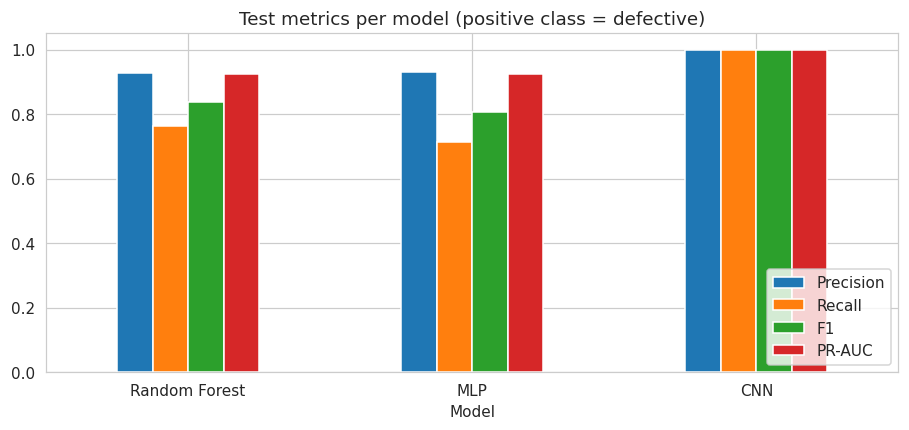

In [37]:
# 6.1 Compare all three models using their test results
comp = pd.DataFrame(RESULTS).T
comp.index.name = "Model"
cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "Train time (s)", "Parameters"]
comp = comp[cols]
for c in cols[:6]:
    comp[c] = comp[c].astype(float).round(4)
comp["Train time (s)"] = comp["Train time (s)"].astype(float).round(1)
display(comp)
print("All three rows are test metrics from each task's own untouched test set.")
print("Like-for-like check for Part A (RF trained on the MLP's subset):")
display(fair)

metrics = ["Precision", "Recall", "F1", "PR-AUC"]
comp[metrics].astype(float).plot(kind="bar", figsize=(10, 4))
plt.title("Test metrics per model (positive class = defective)")
plt.ylim(0, 1.05); plt.xticks(rotation=0); plt.legend(loc="lower right"); plt.show()

**Interpretation (6.3): interpretability and cost**

| | Interpretability | Data needs | Training cost | Inference cost |
|---|---|---|---|---|
| Random Forest | Highest (importances, inspectable trees) | Low–moderate | 157 s on CPU (including grid search) | Low |
| MLP | Low–moderate (needs SHAP or permutation methods) | Moderate | 17 s | Very low |
| CNN | Lowest (learned features, Grad-CAM only) | Highest | 506 s on GPU | Moderate (camera + GPU or edge device) |

The CNN needs more data and compute because each sample is a 128×128 image (16,384 values) rather than 14 numbers, and its convolutional filters must learn visual features from scratch with no pre-trained weights. A Random Forest is the easiest to explain to a quality manager or auditor, because it can say which process variables drive a prediction.

**Interpretation (6.4): over-fitting and under-fitting**

**Random Forest:** deep trees can memorise noise. Cross-validated tuning chose `max_depth=10` and `min_samples_leaf=5`, which limit tree complexity and kept the model from fitting noise.

**MLP:** dropout (0.2), a small network and early stopping on validation PR-AUC (restoring epoch-12 weights) limited over-fitting.

**CNN:** the baseline showed noisy validation loss and a large dense layer. The revised model's augmentation, batch normalisation, dropout and global average pooling closed the train–validation gap and stabilised validation loss.

**Under-fitting:** the tabular models may be limited by the signal in the data rather than by capacity. ROC-AUC stays near 0.75 for both very different models, which suggests the features carry limited information about the defect, and the dominant class (84%) makes accuracy look weak next to the baseline.

## 6.5 Recommendation for deployment

I recommend a two-stage system, because the two data sources answer different questions.

1. **Random Forest on process data as an always-on monitor.** It is cheap, fast and explainable. Its feature importances show engineers which process variable to investigate. It beat the MLP on recall (0.76–0.77 vs 0.71) and F1 (0.84 vs 0.81), with the same ranking quality, and needs less preprocessing. However, it still missed about 24% of defective units at the 0.5 threshold, so it should act as an early-warning signal rather than the only gate.
2. **CNN on final-product images as an end-of-line gate.** It scored perfectly on the held-out casting images, with no false negatives, and catches visual defects that process metrics cannot see. Because that result comes from a single product and fixed camera, it needs validating under real conditions before it is trusted.
3. **The MLP is not recommended** as the primary tabular model. It gave no gain over the Random Forest and adds tuning effort and loss of interpretability.

**Deployment considerations:**
- Choose thresholds to favour recall, since a missed defect costs more than a false alarm. Use a cost-based or minimum-precision rule, because simply maximising F1 predicted every unit as defective (3.9). Send borderline cases to human review.
- Monitor for data drift (sensor recalibration, lighting or camera changes) and retrain periodically.
- Check latency and hardware (edge device or GPU) for the CNN on the line.
- Run a pilot on real SmartFactory data first, because the tabular data is synthetic and the images cover one product.